<a href="https://colab.research.google.com/github/smartypants85/SCUDEM-Hill-Model-RK4/blob/sensitivity/scudem_sensitivity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SCUDEM Problem A: Pediatric Forearm Prosthesis Model
Hill-type muscle model of a child lifting an object with a forearm prosthesis, socket loads, growth over time, and Sobol sensitivity analysis.

**Sections**
1. Basic Hill model (no growth), solved with RK4
2. Growth model parameters (already fitted)
3. Hill model with growth (boys and girls), RK4 in lift time and in age
4. Sobol sensitivity analysis

Run the cells in order (**Runtime → Run all**).

In [ ]:
%pip install -q SALib

## 1. Basic Hill model (no growth)
**Muscle geometry**
$$l_{mt} = \sqrt{h^2 + d_r^2 - 2hd_r\sin\theta}, \qquad \sin\alpha = \frac{h\cos\theta}{l_{mt}}$$
**Hill muscle** (rigid tendon)
$$l_m = l_{mt} - l_{ts}, \quad v = d_r\sin\alpha\,\omega, \quad f_L = \exp\!\left[-\frac{(l_m/l_{opt}-1)^2}{0.45}\right], \quad f_V = \frac{v_{max}-v}{v_{max}+v/A}\ (v\ge 0)$$
$$F_m = F_{max}\,a(t)\,f_L\,f_V, \qquad a(t) = a_0 + a_d\sin^2(\pi t/T_L)\ \text{for } t<T_L$$
**Equation of motion**
$$\frac{d\theta}{dt} = \omega, \qquad \frac{d\omega}{dt} = \frac{F_m\,d_r\sin\alpha - \cos\theta\,(F_{p1}d_g + F_{p2}L)}{I}, \qquad I = \frac{F_{p1}d_g^2 + F_{p2}L^2}{g}$$
**Outputs:** elbow reaction $R_x, R_y$, socket moment $M_{socket}$, and socket pressure $p_{max} = 6M_{socket}/(w s^2)$.

In [1]:

import math
import csv


P = dict(
    h=0.24,        # elbow to biceps origin on humerus (m)
    d_r=0.03,      # elbow to biceps insertion on forearm (m)
    d_g=0.19,      # elbow to prosthesis center of mass (m)
    L=0.25,        # elbow to load in hand (m)
    x_3=0.08,      # elbow to socket rim (m)
    F_p1=0.98,     # prosthesis weight (N)
    F_p2=19.0,     # load weight (N)
    F_max=200.0,   # max isometric biceps force (N)
    l_opt=0.07,    # optimal muscle fiber length (m)
    l_ts=0.16,     # tendon slack length (m)
    v_max=0.7,     # max shortening speed (m/s)
    A=0.25,        # Hill force-velocity constant
    g=9.81,        # gravity (m/s^2)
    a_d=0.2,       # extra activation during the lift (0 to 1)
    T_L=0.6,       # length of the activation burst (s)
    theta0_deg=-10.0,  # starting forearm angle (deg above horizontal)
    omega0=0.0,    # starting angular velocity (rad/s)
    dt=0.005,      # time step (s)
    n_steps=200,   # number of steps (sheet uses 200 rows)
    w=0.05,        # socket width (m)
    s=0.08,        # socket engagement length (m)
    p_tol=100000.0,  # tissue pressure tolerance (Pa)
    a_0=None,      # baseline activation; None = activation that holds the arm at theta0
)


I = (P["F_p1"] * P["d_g"] ** 2 + P["F_p2"] * P["L"] ** 2) / P["g"]
W = P["F_p1"] * P["d_g"] + P["F_p2"] * P["L"]   # weight moment factor (N*m)



def geometry(th):
    """Muscle-tendon length, sin(alpha), fiber length, force-length factor."""
    l_mt = math.sqrt(P["h"] ** 2 + P["d_r"] ** 2 - 2 * P["h"] * P["d_r"] * math.sin(th))
    sin_a = P["h"] * math.cos(th) / l_mt
    l_m = l_mt - P["l_ts"]
    f_L = math.exp(-((l_m / P["l_opt"] - 1) ** 2) / 0.45)
    return l_mt, sin_a, l_m, f_L


def hold_activation(th):
    """Activation needed to hold the arm still at angle th (same as the sheet's a_0)."""
    l_mt, sin_a, l_m, f_L = geometry(th)
    F_needed = math.cos(th) * W / (P["d_r"] * sin_a)
    return F_needed / (P["F_max"] * f_L)


theta0 = math.radians(P["theta0_deg"])
a_0 = P["a_0"] if P["a_0"] is not None else hold_activation(theta0)


def activation(t):
    """a(t) = a_0 + a_d * sin^2(pi t / T_L) for t < T_L, else a_0.  Capped at 1 (max effort)."""
    a = a_0 + (P["a_d"] * math.sin(math.pi * t / P["T_L"]) ** 2 if t < P["T_L"] else 0.0)
    return min(a, 1.0), a  # (used value, uncapped value)


def muscle(t, th, om):
    """Everything the sheet computes in one row, from (t, theta, omega)."""
    l_mt, sin_a, l_m, f_L = geometry(th)
    v = P["d_r"] * sin_a * om                       # shortening speed (m/s)
    if v < 0:
        f_V = 1.0                                   # lengthening: use 1 (first model)
    else:
        f_V = max(0.0, (P["v_max"] - v) / (P["v_max"] + v / P["A"]))
    a, a_raw = activation(t)
    F_m = P["F_max"] * a * f_L * f_V
    dwdt = (F_m * P["d_r"] * sin_a - math.cos(th) * W) / I
    return dict(l_mt=l_mt, sin_a=sin_a, l_m=l_m, v=v, f_L=f_L, f_V=f_V,
                a=a, a_raw=a_raw, F_m=F_m, dwdt=dwdt)


def rhs(t, th, om):
    """Right-hand side of the ODE: returns (d theta/dt, d omega/dt)."""
    return om, muscle(t, th, om)["dwdt"]


def outputs(t, th, om):
    """Row of results, including elbow reaction and socket loads."""
    m = muscle(t, th, om)
    al = m["dwdt"]
    R_x = m["F_m"] * P["d_r"] * math.cos(th) / m["l_mt"] - W / P["g"] * (al * math.sin(th) + om ** 2 * math.cos(th))
    R_y = (P["F_p1"] + P["F_p2"] - m["F_m"] * (P["h"] - P["d_r"] * math.sin(th)) / m["l_mt"]
           + W / P["g"] * (al * math.cos(th) - om ** 2 * math.sin(th)))
    R = math.hypot(R_x, R_y)
    x3 = P["x_3"]
    M_s = (math.cos(th) * (P["F_p1"] * (P["d_g"] - x3) + P["F_p2"] * (P["L"] - x3))
           + al / P["g"] * (P["F_p1"] * P["d_g"] * (P["d_g"] - x3) + P["F_p2"] * P["L"] * (P["L"] - x3)))
    p_max = 6 * M_s / (P["w"] * P["s"] ** 2)
    return dict(t=t, theta=th, omega=om, theta_deg=math.degrees(th), **m,
                R_x=R_x, R_y=R_y, R=R, M_socket=M_s, p_max=p_max)



def rk4(dt=P["dt"], n=P["n_steps"]):
    t, th, om = 0.0, theta0, P["omega0"]
    rows = [outputs(t, th, om)]
    for _ in range(n):
        k1th, k1om = rhs(t, th, om)
        k2th, k2om = rhs(t + dt / 2, th + dt / 2 * k1th, om + dt / 2 * k1om)
        k3th, k3om = rhs(t + dt / 2, th + dt / 2 * k2th, om + dt / 2 * k2om)
        k4th, k4om = rhs(t + dt,     th + dt * k3th,     om + dt * k3om)
        th += dt / 6 * (k1th + 2 * k2th + 2 * k3th + k4th)
        om += dt / 6 * (k1om + 2 * k2om + 2 * k3om + k4om)
        t += dt
        rows.append(outputs(t, th, om))
    return rows



def euler(dt=P["dt"], n=P["n_steps"]):
    t, th, om = 0.0, theta0, P["omega0"]
    rows = [outputs(t, th, om)]
    for _ in range(n):
        dth, dom = rhs(t, th, om)
        th, om, t = th + dt * dth, om + dt * dom, t + dt
        rows.append(outputs(t, th, om))
    return rows


def summary(rows, name):
    peak = lambda k: max(r[k] for r in rows)
    print(f"\n{name}")
    print(f"  Final theta (deg)      {rows[-1]['theta_deg']:.2f}")
    print(f"  Peak F_m (N)           {peak('F_m'):.1f}")
    print(f"  Peak |R| (N)           {peak('R'):.1f}")
    print(f"  Peak M_socket (N*m)    {peak('M_socket'):.3f}")
    print(f"  Peak p_max (Pa)        {peak('p_max'):,.0f}")
    print(f"  Peak p_max / p_tol     {peak('p_max') / P['p_tol']:.2f}")
    print(f"  Peak activation a      {peak('a'):.3f}  (uncapped {peak('a_raw'):.3f})")


if __name__ == "__main__":
    print(f"I = {I:.5f} kg m^2,  a_0 = {a_0:.4f}")
    if a_0 + P["a_d"] > 1:
        print(f"WARNING: a_0 + a_d = {a_0 + P['a_d']:.3f} > 1. The lift needs more than 100% effort;"
              " activation is capped at 1. Lower F_p2 or raise F_max.")

    rk = rk4()
    eu = euler()
    summary(rk, "RK4, dt = %.3f s" % P["dt"])
    summary(eu, "Euler, dt = %.3f s" % P["dt"])


    ref = rk4(P["dt"] / 10, P["n_steps"] * 10)[-1]["theta_deg"]
    print(f"\nFinal theta error vs. reference:  RK4 {rk[-1]['theta_deg'] - ref:+.6f} deg,"
          f"  Euler {eu[-1]['theta_deg'] - ref:+.6f} deg")


    cols = ["t", "theta", "omega", "theta_deg", "l_mt", "sin_a", "l_m", "v", "f_L", "f_V",
            "a", "F_m", "dwdt", "R_x", "R_y", "R", "M_socket", "p_max"]
    with open("rk4_results.csv", "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(cols)
        for r in rk:
            wr.writerow([f"{r[c]:.6g}" for c in cols])
    print("\nSaved rk4_results.csv")


I = 0.12466 kg m^2,  a_0 = 0.9649

RK4, dt = 0.005 s
  Final theta (deg)      4.12
  Peak F_m (N)           174.2
  Peak |R| (N)           153.9
  Peak M_socket (N*m)    3.395
  Peak p_max (Pa)        63,657
  Peak p_max / p_tol     0.64
  Peak activation a      1.000  (uncapped 1.165)

Euler, dt = 0.005 s
  Final theta (deg)      3.89
  Peak F_m (N)           174.3
  Peak |R| (N)           153.9
  Peak M_socket (N*m)    3.395
  Peak p_max (Pa)        63,660
  Peak p_max / p_tol     0.64
  Peak activation a      1.000  (uncapped 1.165)

Final theta error vs. reference:  RK4 +0.001332 deg,  Euler -0.230053 deg

Saved rk4_results.csv


## 2. Growth model parameters (already fitted, not refit here)
**Logistic (Verhulst) growth**, with $\lambda$ = size / size at age 5:
$$\frac{d\lambda}{dt_a} = k\lambda\left(1-\frac{\lambda}{\lambda_\infty}\right), \qquad \lambda(t_a) = \frac{\lambda_\infty}{1+(\lambda_\infty-1)e^{-k(t_a-5)}}$$

| | Boys | Girls |
|---|---|---|
| $k$ (per year) | 0.2069 ± 0.0257 | 0.2460 ± 0.0275 |
| $\lambda_\infty$ | 1.8575 ± 0.0626 | 1.6760 ± 0.0453 |
| Arm length at 5 | 21.90 cm | 21.76 cm |
| Fitted adult arm (NHANES 20–29) | 40.7 cm (39.4 cm) | 36.5 cm (35.9 cm) |
| Arm RMSE | 0.73 cm | 0.55 cm |
| $F_{max0}$ | 328.8 ± 10.5 N | 296.1 ± 12.1 N |
| Moment-arm ratio $r$ | 0.173 | 0.174 |
| Strength RMSE | 1.10 kgf | 1.21 kgf |
| Implied adult $F_{max} = F_{max0}\lambda_\infty^2$ | 1134 N | 832 N |

These values are used directly in Sections 3 and 4.

## 3. Hill model with growth
Two clocks: lift time $t$ (seconds) and age $t_a$ (years). At each age the lift is re-run with
$$h, d_r, x_3, l_{opt}, c, \ell_r \propto \lambda, \qquad F_{max} = F_{max0}\lambda^2, \qquad d_g = x_3 + a_p,\ L = x_3 + b_p$$
Tendon lag: $\dfrac{dl_{ts}}{dt_a} = \dfrac{l_{ts,0}\lambda - l_{ts}}{T_g}$. Socket checks: $p_{total} = p_{fit} + p_{weights}$ with $p_{fit} = k_s\dfrac{c-c_s}{c_s}$, and stump ratio $\ell_r/(\ell_{r0}+\text{gap})$.
Uses the fitted values from Section 2.

In [2]:
"""
RK4 for the elbow-lift model WITH GROWTH (advanced Hill model).

Two clocks:
  slow (age t_a, years):  d(lambda)/dt_a = k*lambda*(1 - lambda/lambda_inf)
                          d(l_ts)/dt_a   = (l_ts0*lambda - l_ts)/T_g        (tendon lag)
  fast (lift t, seconds): d(theta)/dt = omega
                          d(omega)/dt = [F_m*d_r*sin(alpha) - cos(theta)*(F_p1*d_g + F_p2*L)] / I
Both clocks are integrated with 4th-order Runge-Kutta. At every age the lift ODE is
re-run with the parameters scaled by lambda, and the socket / elbow / effort checks are recorded.
"""
import math
import csv


SEXES = {
    "boys":  dict(k=0.2069, lam_inf=1.8575, F_max0=328.8),
    "girls": dict(k=0.2460, lam_inf=1.6760, F_max0=296.1),
}


BASE = dict(
    h0=0.24, d_r0=0.03, x_30=0.08,          # body lengths at age_0 (m), scale with lambda
    d_g0=0.19, L0=0.25,                     # prosthesis CoM and load distance from elbow at age_0 (m)
    F_p1=0.98, F_p20=19.0, n_L=0,           # prosthesis weight, load weight (N); load ~ lambda^n_L
    l_opt0=0.07, l_ts0=0.16,                # muscle optimal fiber length, tendon slack length (m)
    A=0.25, g=9.81,
    a_d=0.2, T_L=0.6,                       # extra activation, burst length (s)
    theta0_deg=-10.0, omega0=0.0,
    dt=0.005, n_steps=200,                  # lift time step (s) and number of steps
    w=0.05, s=0.08, p_tol=100000.0,         # socket width, engagement length (m); tolerance (Pa)
)

GROW = dict(
    age0=5.0, age_end=18.0, dt_a=0.25,      # years
    T_g=0.5,                                # tendon catch-up time (years)
    c0=0.16, c_s=0.165, k_s=300000.0,       # stump circumference, socket circumference (m), tissue stiffness (Pa)
    l_r0=0.16, gap=0.02,                    # stump length at age_0, extra socket depth (m)
)
A_P = BASE["d_g0"] - BASE["x_30"]   # socket rim -> prosthesis CoM (fixed)
B_P = BASE["L0"] - BASE["x_30"]     # socket rim -> load (fixed)



def growth_rhs(lam, l_ts, k, lam_inf):
    dlam = k * lam * (1 - lam / lam_inf)
    dlts = (BASE["l_ts0"] * lam - l_ts) / GROW["T_g"]
    return dlam, dlts


def growth_rk4_step(lam, l_ts, k, lam_inf, h):
    k1 = growth_rhs(lam, l_ts, k, lam_inf)
    k2 = growth_rhs(lam + h / 2 * k1[0], l_ts + h / 2 * k1[1], k, lam_inf)
    k3 = growth_rhs(lam + h / 2 * k2[0], l_ts + h / 2 * k2[1], k, lam_inf)
    k4 = growth_rhs(lam + h * k3[0], l_ts + h * k3[1], k, lam_inf)
    lam += h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
    l_ts += h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return lam, l_ts


def scaled_params(lam, l_ts, F_max0):
    """Parameters at the current age. Body scales with lambda; prosthesis stays fixed."""
    x_3 = BASE["x_30"] * lam
    l_opt = BASE["l_opt0"] * lam
    return dict(
        h=BASE["h0"] * lam,
        d_r=BASE["d_r0"] * lam,
        x_3=x_3,
        d_g=x_3 + A_P,                       # prosthesis rides on the growing stump
        L=x_3 + B_P,
        F_max=F_max0 * lam ** 2,
        l_opt=l_opt,
        l_ts=l_ts,
        v_max=10 * l_opt,
        F_p1=BASE["F_p1"],
        F_p2=BASE["F_p20"] * lam ** BASE["n_L"],
    )


class Lift:
    def __init__(self, P):
        self.P = P
        self.I = (P["F_p1"] * P["d_g"] ** 2 + P["F_p2"] * P["L"] ** 2) / BASE["g"]
        self.W = P["F_p1"] * P["d_g"] + P["F_p2"] * P["L"]
        self.theta0 = math.radians(BASE["theta0_deg"])
        self.a_0 = self.hold_activation(self.theta0)

    def geometry(self, th):
        P = self.P
        l_mt = math.sqrt(P["h"] ** 2 + P["d_r"] ** 2 - 2 * P["h"] * P["d_r"] * math.sin(th))
        sin_a = P["h"] * math.cos(th) / l_mt
        l_m = l_mt - P["l_ts"]
        f_L = math.exp(-((l_m / P["l_opt"] - 1) ** 2) / 0.45)
        return l_mt, sin_a, l_m, f_L

    def hold_activation(self, th):
        l_mt, sin_a, l_m, f_L = self.geometry(th)
        return math.cos(th) * self.W / (self.P["d_r"] * sin_a) / (self.P["F_max"] * f_L)

    def activation(self, t):
        a = self.a_0 + (BASE["a_d"] * math.sin(math.pi * t / BASE["T_L"]) ** 2 if t < BASE["T_L"] else 0.0)
        return min(a, 1.0), a                   # capped at maximum effort, and uncapped value

    def muscle(self, t, th, om):
        P = self.P
        l_mt, sin_a, l_m, f_L = self.geometry(th)
        v = P["d_r"] * sin_a * om
        f_V = 1.0 if v < 0 else max(0.0, (P["v_max"] - v) / (P["v_max"] + v / BASE["A"]))
        a, a_raw = self.activation(t)
        F_m = P["F_max"] * a * f_L * f_V
        dwdt = (F_m * P["d_r"] * sin_a - math.cos(th) * self.W) / self.I
        return l_mt, F_m, a_raw, dwdt

    def rhs(self, t, th, om):
        return om, self.muscle(t, th, om)[3]

    def outputs(self, t, th, om):
        P, g = self.P, BASE["g"]
        l_mt, F_m, a_raw, al = self.muscle(t, th, om)
        R_x = F_m * P["d_r"] * math.cos(th) / l_mt - self.W / g * (al * math.sin(th) + om ** 2 * math.cos(th))
        R_y = (P["F_p1"] + P["F_p2"] - F_m * (P["h"] - P["d_r"] * math.sin(th)) / l_mt
               + self.W / g * (al * math.cos(th) - om ** 2 * math.sin(th)))
        M_s = (math.cos(th) * (P["F_p1"] * A_P + P["F_p2"] * B_P)
               + al / g * (P["F_p1"] * P["d_g"] * A_P + P["F_p2"] * P["L"] * B_P))
        return dict(F_m=F_m, a_raw=a_raw, R=math.hypot(R_x, R_y), M_socket=M_s, theta_deg=math.degrees(th))

    def run(self):
        dt, n = BASE["dt"], BASE["n_steps"]
        t, th, om = 0.0, self.theta0, BASE["omega0"]
        rows = [self.outputs(t, th, om)]
        for _ in range(n):
            k1 = self.rhs(t, th, om)
            k2 = self.rhs(t + dt / 2, th + dt / 2 * k1[0], om + dt / 2 * k1[1])
            k3 = self.rhs(t + dt / 2, th + dt / 2 * k2[0], om + dt / 2 * k2[1])
            k4 = self.rhs(t + dt, th + dt * k3[0], om + dt * k3[1])
            th += dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
            om += dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
            t += dt
            rows.append(self.outputs(t, th, om))
        return rows

def simulate(sex, fit):
    lam, l_ts, age = 1.0, BASE["l_ts0"], GROW["age0"]
    table = []
    while age <= GROW["age_end"] + 1e-9:
        P = scaled_params(lam, l_ts, fit["F_max0"])
        lift = Lift(P)
        rows = lift.run()

        peak_M = max(r["M_socket"] for r in rows)
        p_weights = 6 * peak_M / (BASE["w"] * BASE["s"] ** 2)
        c = GROW["c0"] * lam
        p_fit = GROW["k_s"] * (c - GROW["c_s"]) / GROW["c_s"] if c > GROW["c_s"] else 0.0
        p_total = p_fit + p_weights
        stump_ratio = GROW["l_r0"] * lam / (GROW["l_r0"] + GROW["gap"])

        table.append(dict(
            age=age, lam=lam, l_ts=l_ts, F_max=P["F_max"], a_0=lift.a_0,
            peak_a=max(r["a_raw"] for r in rows), peak_F_m=max(r["F_m"] for r in rows),
            peak_R=max(r["R"] for r in rows), final_theta=rows[-1]["theta_deg"],
            peak_M_socket=peak_M, p_weights=p_weights, p_fit=p_fit, p_total=p_total,
            p_ratio=p_total / BASE["p_tol"], stump_ratio=stump_ratio,
        ))
        lam, l_ts = growth_rk4_step(lam, l_ts, fit["k"], fit["lam_inf"], GROW["dt_a"])
        age += GROW["dt_a"]
    return table


def first_age(table, key, limit=1.0):
    for r in table:
        if r[key] > limit:
            return r["age"]
    return None


if __name__ == "__main__":
    for sex, fit in SEXES.items():
        table = simulate(sex, fit)
        fmt = lambda a: "not reached" if a is None else f"{a:.2f}"
        a_p, a_s, a_e = first_age(table, "p_ratio"), first_age(table, "stump_ratio"), first_age(table, "peak_a")
        crossed = [a for a in (a_p, a_s, a_e) if a is not None]
        print(f"\n=== {sex} ===  (k = {fit['k']}, lambda_inf = {fit['lam_inf']}, F_max0 = {fit['F_max0']} N)")
        print(f"  Socket pressure > p_tol at age : {fmt(a_p)}")
        print(f"  Stump outgrows socket at age   : {fmt(a_s)}")
        print(f"  Lift needs > 100% effort at age: {fmt(a_e)}")
        print(f"  Earliest adjust/replace age    : {fmt(min(crossed) if crossed else None)}")
        print(f"  {'age':>5} {'lambda':>7} {'F_max':>7} {'peak a':>7} {'peak|R|':>8} {'p_fit':>8} {'p_total':>8} {'p/p_tol':>7} {'stump':>6}")
        for r in table[::4]:   # print once per year
            print(f"  {r['age']:5.1f} {r['lam']:7.3f} {r['F_max']:7.0f} {r['peak_a']:7.3f} {r['peak_R']:8.1f}"
                  f" {r['p_fit']:8.0f} {r['p_total']:8.0f} {r['p_ratio']:7.2f} {r['stump_ratio']:6.2f}")
        fn = f"growth_results_{sex}.csv"
        with open(fn, "w", newline="") as f:
            wr = csv.DictWriter(f, fieldnames=list(table[0].keys()))
            wr.writeheader()
            for r in table:
                wr.writerow({k: f"{v:.6g}" for k, v in r.items()})
        print(f"  Saved {fn}")



=== boys ===  (k = 0.2069, lambda_inf = 1.8575, F_max0 = 328.8 N)
  Socket pressure > p_tol at age : 6.50
  Stump outgrows socket at age   : 6.50
  Lift needs > 100% effort at age: not reached
  Earliest adjust/replace age    : 6.50
    age  lambda   F_max  peak a  peak|R|    p_fit  p_total p/p_tol  stump
    5.0   1.000     329   0.787    171.8        0    71946    0.72   0.89
    6.0   1.094     394   0.714    164.5    18379    92424    0.92   0.97
    7.0   1.185     462   0.617    160.2    44857   121626    1.22   1.05
    8.0   1.271     532   0.542    157.5    69868   149553    1.50   1.13
    9.0   1.351     600   0.488    156.0    93046   175657    1.76   1.20
   10.0   1.424     666   0.448    155.1   114148   199588    2.00   1.27
   11.0   1.489     729   0.419    154.8   133053   221158    2.21   1.32
   12.0   1.546     786   0.396    154.8   149746   240292    2.40   1.37
   13.0   1.596     838   0.380    154.9   164298   257040    2.57   1.42
   14.0   1.639     883   

## 4. Sobol sensitivity analysis
Every parameter varies ±25% around its baseline. The tendon slack length is set from the geometry, $l_{ts} = \sqrt{h^2+d_r^2} - \rho\,l_{opt}$, so every sample is a physically consistent muscle; $\rho = l_m/l_{opt}$ is varied instead.
Outputs: $p_{max}(t)$ and $F_m(t)$ over the lift, and the adjust/replace age for boys and girls.

In [4]:
! pip install SALib
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
from SALib.sample import saltelli
from SALib.analyze import sobol
import numpy as np
import matplotlib.pyplot as plt

POINTS = 2**10          # Saltelli base sample size (same as MMR code)
BOUND_FACTOR = 0.25     # +/-25% around each baseline
SEED = 1

#baisc lift
BASIC = [  # (key, symbol, baseline)
    ("h",     r"$h$",          0.24),
    ("d_r",   r"$d_r$",        0.03),
    ("d_g",   r"$d_g$",        0.19),
    ("L",     r"$L$",          0.25),
    ("x_3",   r"$x_3$",        0.08),
    ("F_p1",  r"$F_{p1}$",     0.98),
    ("F_p2",  r"$F_{p2}$",     19.0),
    ("F_max", r"$F_{max}$",    200.0),
    ("l_opt", r"$l_{opt}$",    0.07),
    ("rho",   r"$\rho$",       (np.sqrt(0.24**2 + 0.03**2) - 0.16) / 0.07),   # fiber/optimal length ratio at theta=0
    ("v_max", r"$v_{max}$",    0.7),
    ("A",     r"$A$",          0.25),
    ("a_d",   r"$a_d$",        0.2),
    ("T_L",   r"$T_L$",        0.6),
    ("th0",   r"$\theta_0$",   -10.0),   # degrees
    ("w",     r"$w$",          0.05),
    ("s",     r"$s$",          0.08),
]
G = 9.81
DT, N_STEPS = 0.005, 200
SAVE_EVERY = 10                       # record outputs every 0.05 s
LIFT_T = np.arange(SAVE_EVERY, N_STEPS + 1, SAVE_EVERY) * DT


def bounds_for(table):
    out = []
    for _, _, b in table:
        lo, hi = b * (1 - BOUND_FACTOR), b * (1 + BOUND_FACTOR)
        out.append([min(lo, hi), max(lo, hi)])
    return out


def lift_batch(X):
    """Vectorized RK4 lift for every sample row of X. Returns p_max(t), F_m(t) at LIFT_T."""
    p = {key: X[:, i] for i, (key, _, _) in enumerate(BASIC)}
    # tendon slack length tied to geometry so every sample is a consistent muscle:
    p["l_ts"] = np.sqrt(p["h"] ** 2 + p["d_r"] ** 2) - p["rho"] * p["l_opt"]
    W = p["F_p1"] * p["d_g"] + p["F_p2"] * p["L"]
    I = (p["F_p1"] * p["d_g"] ** 2 + p["F_p2"] * p["L"] ** 2) / G

    def geom(th):
        l_mt = np.sqrt(p["h"] ** 2 + p["d_r"] ** 2 - 2 * p["h"] * p["d_r"] * np.sin(th))
        sin_a = p["h"] * np.cos(th) / l_mt
        f_L = np.exp(-(((l_mt - p["l_ts"]) / p["l_opt"] - 1) ** 2) / 0.45)
        return l_mt, sin_a, f_L

    th0 = np.radians(p["th0"])
    _, sa0, fL0 = geom(th0)
    a0 = np.cos(th0) * W / (p["d_r"] * sa0) / (p["F_max"] * fL0)   # hold activation at theta0

    def muscle(t, th, om):
        l_mt, sin_a, f_L = geom(th)
        v = p["d_r"] * sin_a * om
        f_V = np.where(v < 0, 1.0, np.maximum(0.0, (p["v_max"] - v) / (p["v_max"] + v / p["A"])))
        burst = np.where(t < p["T_L"], p["a_d"] * np.sin(np.pi * t / p["T_L"]) ** 2, 0.0)
        a = np.minimum(a0 + burst, 1.0)                              # effort capped at 100%
        F_m = p["F_max"] * a * f_L * f_V
        dwdt = (F_m * p["d_r"] * sin_a - np.cos(th) * W) / I
        return F_m, dwdt

    def socket_p(th, dwdt):
        ap, bp = p["d_g"] - p["x_3"], p["L"] - p["x_3"]
        M = (np.cos(th) * (p["F_p1"] * ap + p["F_p2"] * bp)
             + dwdt / G * (p["F_p1"] * p["d_g"] * ap + p["F_p2"] * p["L"] * bp))
        return 6 * M / (p["w"] * p["s"] ** 2)

    t, th, om = 0.0, th0, np.zeros_like(th0)
    P_out, F_out = [], []
    for n in range(1, N_STEPS + 1):
        k1 = (om, muscle(t, th, om)[1])
        k2 = (om + DT / 2 * k1[1], muscle(t + DT / 2, th + DT / 2 * k1[0], om + DT / 2 * k1[1])[1])
        k3 = (om + DT / 2 * k2[1], muscle(t + DT / 2, th + DT / 2 * k2[0], om + DT / 2 * k2[1])[1])
        k4 = (om + DT * k3[1], muscle(t + DT, th + DT * k3[0], om + DT * k3[1])[1])
        th = th + DT / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        om = om + DT / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
        t += DT
        if n % SAVE_EVERY == 0:
            F_m, dwdt = muscle(t, th, om)
            P_out.append(socket_p(th, dwdt))
            F_out.append(F_m)
    return np.array(P_out), np.array(F_out)     # shape (time points, samples)


# growth
SEXES = {
    "boys":  dict(k=0.2069, lam_inf=1.8575, F_max0=328.8),
    "girls": dict(k=0.2460, lam_inf=1.6760, F_max0=296.1),
}
AGE0, AGE_END, DT_A = 5.0, 18.0, 0.05     # fine age step so the replace age is smooth


def growth_table(sex):
    f = SEXES[sex]
    return [
        ("k",      r"$k$",            f["k"]),
        ("lam_inf",r"$\lambda_\infty$", f["lam_inf"]),
        ("F_max0", r"$F_{max0}$",     f["F_max0"]),
        ("h0",     r"$h_0$",          0.24),
        ("d_r0",   r"$d_{r0}$",       0.03),
        ("x_30",   r"$x_{30}$",       0.08),
        ("d_g0",   r"$d_{g0}$",       0.19),
        ("L0",     r"$L_0$",          0.25),
        ("F_p1",   r"$F_{p1}$",       0.98),
        ("F_p20",  r"$F_{p2}$",       19.0),
        ("l_opt0", r"$l_{opt0}$",     0.07),
        ("rho",    r"$\rho$",         (np.sqrt(0.24**2 + 0.03**2) - 0.16) / 0.07),
        ("T_g",    r"$T_g$",          0.5),
        ("c0",     r"$c_0$",          0.16),
        ("c_s",    r"$c_s$",          0.165),
        ("k_s",    r"$k_s$",          300000.0),
        ("l_r0",   r"$\ell_{r0}$",    0.16),
        ("gap",    r"$gap$",          0.02),
        ("w",      r"$w$",            0.05),
        ("s",      r"$s$",            0.08),
        ("p_tol",  r"$p_{tol}$",      100000.0),
    ]


def crossing_age(ages, ratio):
    """First age where ratio passes 1, linearly interpolated. AGE_END if never crossed."""
    above = ratio > 1.0
    out = np.full(ratio.shape[1], AGE_END)
    any_above = above.any(axis=0)
    idx = np.argmax(above, axis=0)
    for j in np.where(any_above)[0]:
        i = idx[j]
        if i == 0:
            out[j] = ages[0]
        else:
            r0, r1 = ratio[i - 1, j], ratio[i, j]
            out[j] = ages[i - 1] + (1.0 - r0) / (r1 - r0) * (ages[i] - ages[i - 1])
    return out


def growth_batch(X, table):
    p = {key: X[:, i] for i, (key, _, _) in enumerate(table)}
    p["l_ts0"] = np.sqrt(p["h0"] ** 2 + p["d_r0"] ** 2) - p["rho"] * p["l_opt0"]
    a_p, b_p = p["d_g0"] - p["x_30"], p["L0"] - p["x_30"]
    M = p["F_p1"] * a_p + p["F_p20"] * b_p                 # static socket moment, arm horizontal
    p_w = 6 * M / (p["w"] * p["s"] ** 2)

    def rhs(lam, lts):
        return p["k"] * lam * (1 - lam / p["lam_inf"]), (p["l_ts0"] * lam - lts) / p["T_g"]

    ages = np.arange(AGE0, AGE_END + 1e-9, DT_A)
    lam, lts = np.ones(len(X)), p["l_ts0"].copy()
    P_ratio, S_ratio, A_ratio = [], [], []
    for _ in ages:
        # checks at this age
        h, d_r, x3 = p["h0"] * lam, p["d_r0"] * lam, p["x_30"] * lam
        d_g, L = x3 + a_p, x3 + b_p
        l_mt = np.sqrt(h ** 2 + d_r ** 2)
        f_L = np.exp(-(((l_mt - lts) / (p["l_opt0"] * lam) - 1) ** 2) / 0.45)
        F_hold = (p["F_p1"] * d_g + p["F_p20"] * L) * l_mt / (h * d_r)
        c = p["c0"] * lam
        p_fit = np.where(c > p["c_s"], p["k_s"] * (c - p["c_s"]) / p["c_s"], 0.0)
        P_ratio.append((p_fit + p_w) / p["p_tol"])
        S_ratio.append(p["l_r0"] * lam / (p["l_r0"] + p["gap"]))
        A_ratio.append(F_hold / (p["F_max0"] * lam ** 2 * f_L))
        # RK4 step in age
        k1 = rhs(lam, lts)
        k2 = rhs(lam + DT_A / 2 * k1[0], lts + DT_A / 2 * k1[1])
        k3 = rhs(lam + DT_A / 2 * k2[0], lts + DT_A / 2 * k2[1])
        k4 = rhs(lam + DT_A * k3[0], lts + DT_A * k3[1])
        lam = lam + DT_A / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        lts = lts + DT_A / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    P_ratio, S_ratio, A_ratio = map(np.array, (P_ratio, S_ratio, A_ratio))
    ages_all = np.stack([crossing_age(ages, R) for R in (P_ratio, S_ratio, A_ratio)])
    which = np.bincount(ages_all.argmin(axis=0), minlength=3) / ages_all.shape[1]
    print(f"   first limit crossed: pressure {which[0]:.0%}, stump outgrown {which[1]:.0%}, effort {which[2]:.0%}")
    return ages_all.min(axis=0)       # earliest adjust/replace age



plt.rcParams.update({'font.size': 22, 'axes.labelsize': 28, 'xtick.labelsize': 22,
                     'ytick.labelsize': 22, 'legend.fontsize': 17})
PLOT_COLORS = ["red", "gold", "green", "blue", "purple", "orange", "brown", "pink", "gray", "cyan",
               "olive", "black", "magenta", "navy", "teal", "lime", "coral", "darkviolet", "darkred", "darkgreen"]
PLOT_LINESTYLES = ["-", "--", "-.", ":"]


def get_plot_style(jj):
    return PLOT_COLORS[jj % len(PLOT_COLORS)], PLOT_LINESTYLES[(jj // len(PLOT_COLORS)) % len(PLOT_LINESTYLES)]


def plot_indices(t, Si, symbols, ylabel, filename):
    fig, ax1 = plt.subplots(figsize=(15, 9))
    for jj, sym in enumerate(symbols):
        color, ls = get_plot_style(jj)
        ax1.plot(t, Si[:, jj], color=color, linestyle=ls, linewidth=3, label=sym)
    ax1.set_ylim([-0.1, 1.1]); ax1.set_xlim([0, t[-1]])
    ax1.legend(loc='best', fontsize=17, ncol=3)
    ax1.set_ylabel(ylabel, fontsize=28); ax1.set_xlabel("Lift time (s)", fontsize=28)
    fig.tight_layout(); plt.savefig(filename, dpi=300, bbox_inches='tight'); plt.close()


def plot_bars(S1, S1c, ST, STc, symbols, title, filename):
    x = np.arange(len(symbols)); wbar = 0.4
    fig, ax = plt.subplots(figsize=(17, 8))
    ax.bar(x - wbar / 2, S1, wbar, yerr=S1c, color="steelblue", capsize=4, label="First-order")
    ax.bar(x + wbar / 2, ST, wbar, yerr=STc, color="darkorange", capsize=4, label="Total-order")
    ax.set_xticks(x); ax.set_xticklabels(symbols, rotation=45, ha="right")
    ax.set_ylim([0, 1.1]); ax.set_ylabel("Sobol index", fontsize=28); ax.set_title(title, fontsize=24)
    ax.legend(fontsize=17); fig.tight_layout(); plt.savefig(filename, dpi=300, bbox_inches='tight'); plt.close()


def report(names, S1, ST, label):
    order = np.argsort(-ST)
    print(f"\n{label}: top parameters by total-order index")
    for j in order[:6]:
        print(f"   {names[j]:>8}   S1 = {S1[j]:.3f}   ST = {ST[j]:.3f}")



if __name__ == "__main__":

    names = [k for k, _, _ in BASIC]; syms = [s for _, s, _ in BASIC]
    problem = {'num_vars': len(BASIC), 'names': names, 'bounds': bounds_for(BASIC)}
    X = saltelli.sample(problem, POINTS)
    print(f"Basic lift model: {len(X)} samples")
    P_t, F_t = lift_batch(X)
    for out_name, Y in (("p_max", P_t), ("F_m", F_t)):
        S1 = np.zeros((len(LIFT_T), len(names))); ST = np.zeros_like(S1)
        for i in range(len(LIFT_T)):
            res = sobol.analyze(problem, Y[i], print_to_console=False, seed=SEED)
            S1[i], ST[i] = np.clip(res['S1'], 0, 1), np.clip(res['ST'], 0, 1)
        plot_indices(LIFT_T, S1, syms, rf"First-order indices ({out_name})", f"Sensitivity_First_order_{out_name}.png")
        plot_indices(LIFT_T, ST, syms, rf"Total-order indices ({out_name})", f"Sensitivity_Total_order_{out_name}.png")

        res = sobol.analyze(problem, Y.max(axis=0), print_to_console=False, seed=SEED)
        plot_bars(np.clip(res['S1'], 0, 1), res['S1_conf'], np.clip(res['ST'], 0, 1), res['ST_conf'],
                  syms, f"Peak {out_name} over the lift", f"Sensitivity_peak_{out_name}.png")
        report(names, res['S1'], res['ST'], f"Peak {out_name}")
        np.save(f"Si_{out_name}_F.npy", S1); np.save(f"Si_{out_name}_T.npy", ST)


    for sex in SEXES:
        table = growth_table(sex)
        names = [k for k, _, _ in table]; syms = [s for _, s, _ in table]
        problem = {'num_vars': len(table), 'names': names, 'bounds': bounds_for(table)}
        X = saltelli.sample(problem, POINTS)
        print(f"\nGrowth model ({sex}): {len(X)} samples")
        Y = growth_batch(X, table)
        print(f"   replace age: mean {Y.mean():.2f}, 5-95% range {np.percentile(Y, 5):.2f}-{np.percentile(Y, 95):.2f} yr")
        res = sobol.analyze(problem, Y, print_to_console=False, seed=SEED)
        plot_bars(np.clip(res['S1'], 0, 1), res['S1_conf'], np.clip(res['ST'], 0, 1), res['ST_conf'],
                  syms, f"Adjust/replace age ({sex})", f"Sensitivity_replace_age_{sex}.png")
        report(names, res['S1'], res['ST'], f"Replace age ({sex})")
        np.save(f"replace_age_samples_{sex}.npy", Y)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.1/800.1 kB 9.2 MB/s  0:00:00
Basic lift model: 36864 samples

Peak p_max: top parameters by total-order index
          s   S1 = 0.477   ST = 0.520
        rho   S1 = 0.100   ST = 0.138
          w   S1 = 0.127   ST = 0.136
          L   S1 = 0.071   ST = 0.124
      F_max   S1 = 0.054   ST = 0.077
        d_r   S1 = 0.049   ST = 0.061

Peak F_m: top parameters by total-order index
        rho   S1 = 0.358   ST = 0.524
      F_max   S1 = 0.200   ST = 0.308
        d_r   S1 = 0.050   ST = 0.153
          L   S1 = 0.035   ST = 0.151
       F_p2   S1 = 0.034   ST = 0.122
      v_max   S1 = 0.002   ST = 0.005

Growth model (boys): 45056 samples
   first limit crossed: pressure 51%, stump outgrown 47%, effort 3%
   replace age: mean 5.82, 5-95% range 5.00-7.22 yr

Replace age (boys): top parameters by total-order index
        c_s   S1 = 0.111   ST = 0.397
         c0   S1 = 0.120   ST = 0.304
          s   S1 = 0.053   ST = 0.221
         L0 

Sensitivity_First_order_F_m.png


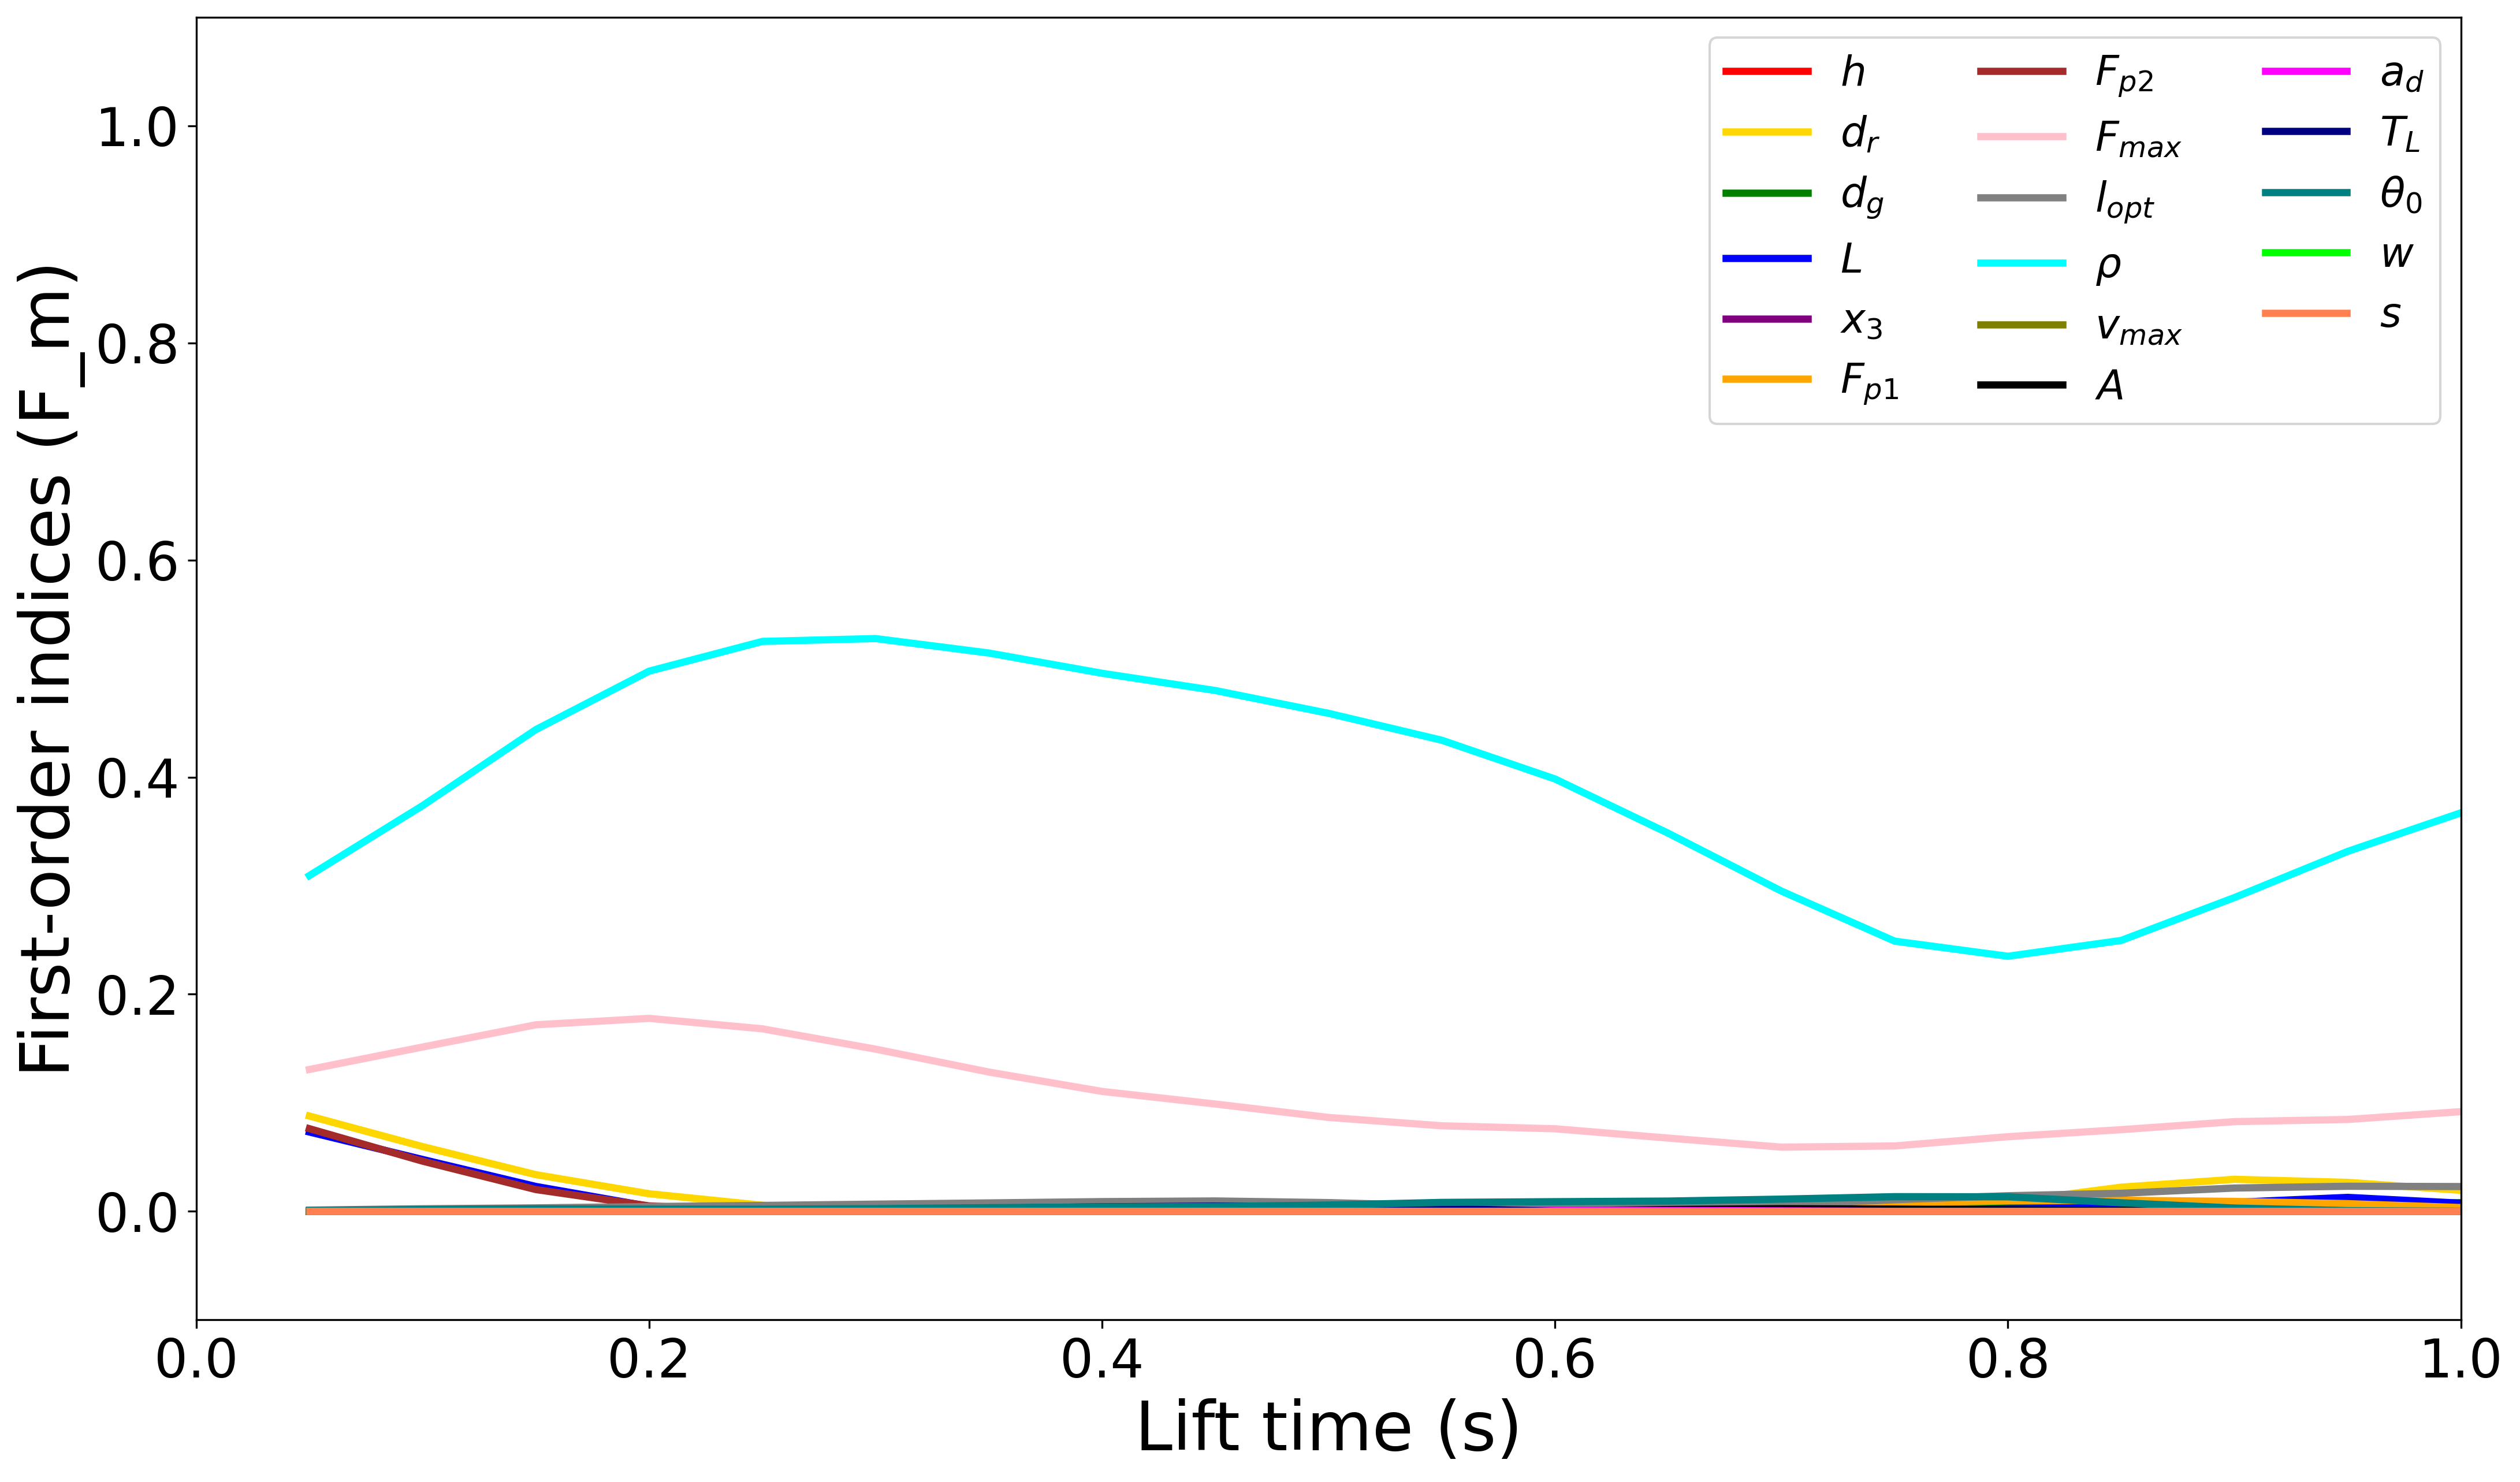

Sensitivity_First_order_p_max.png


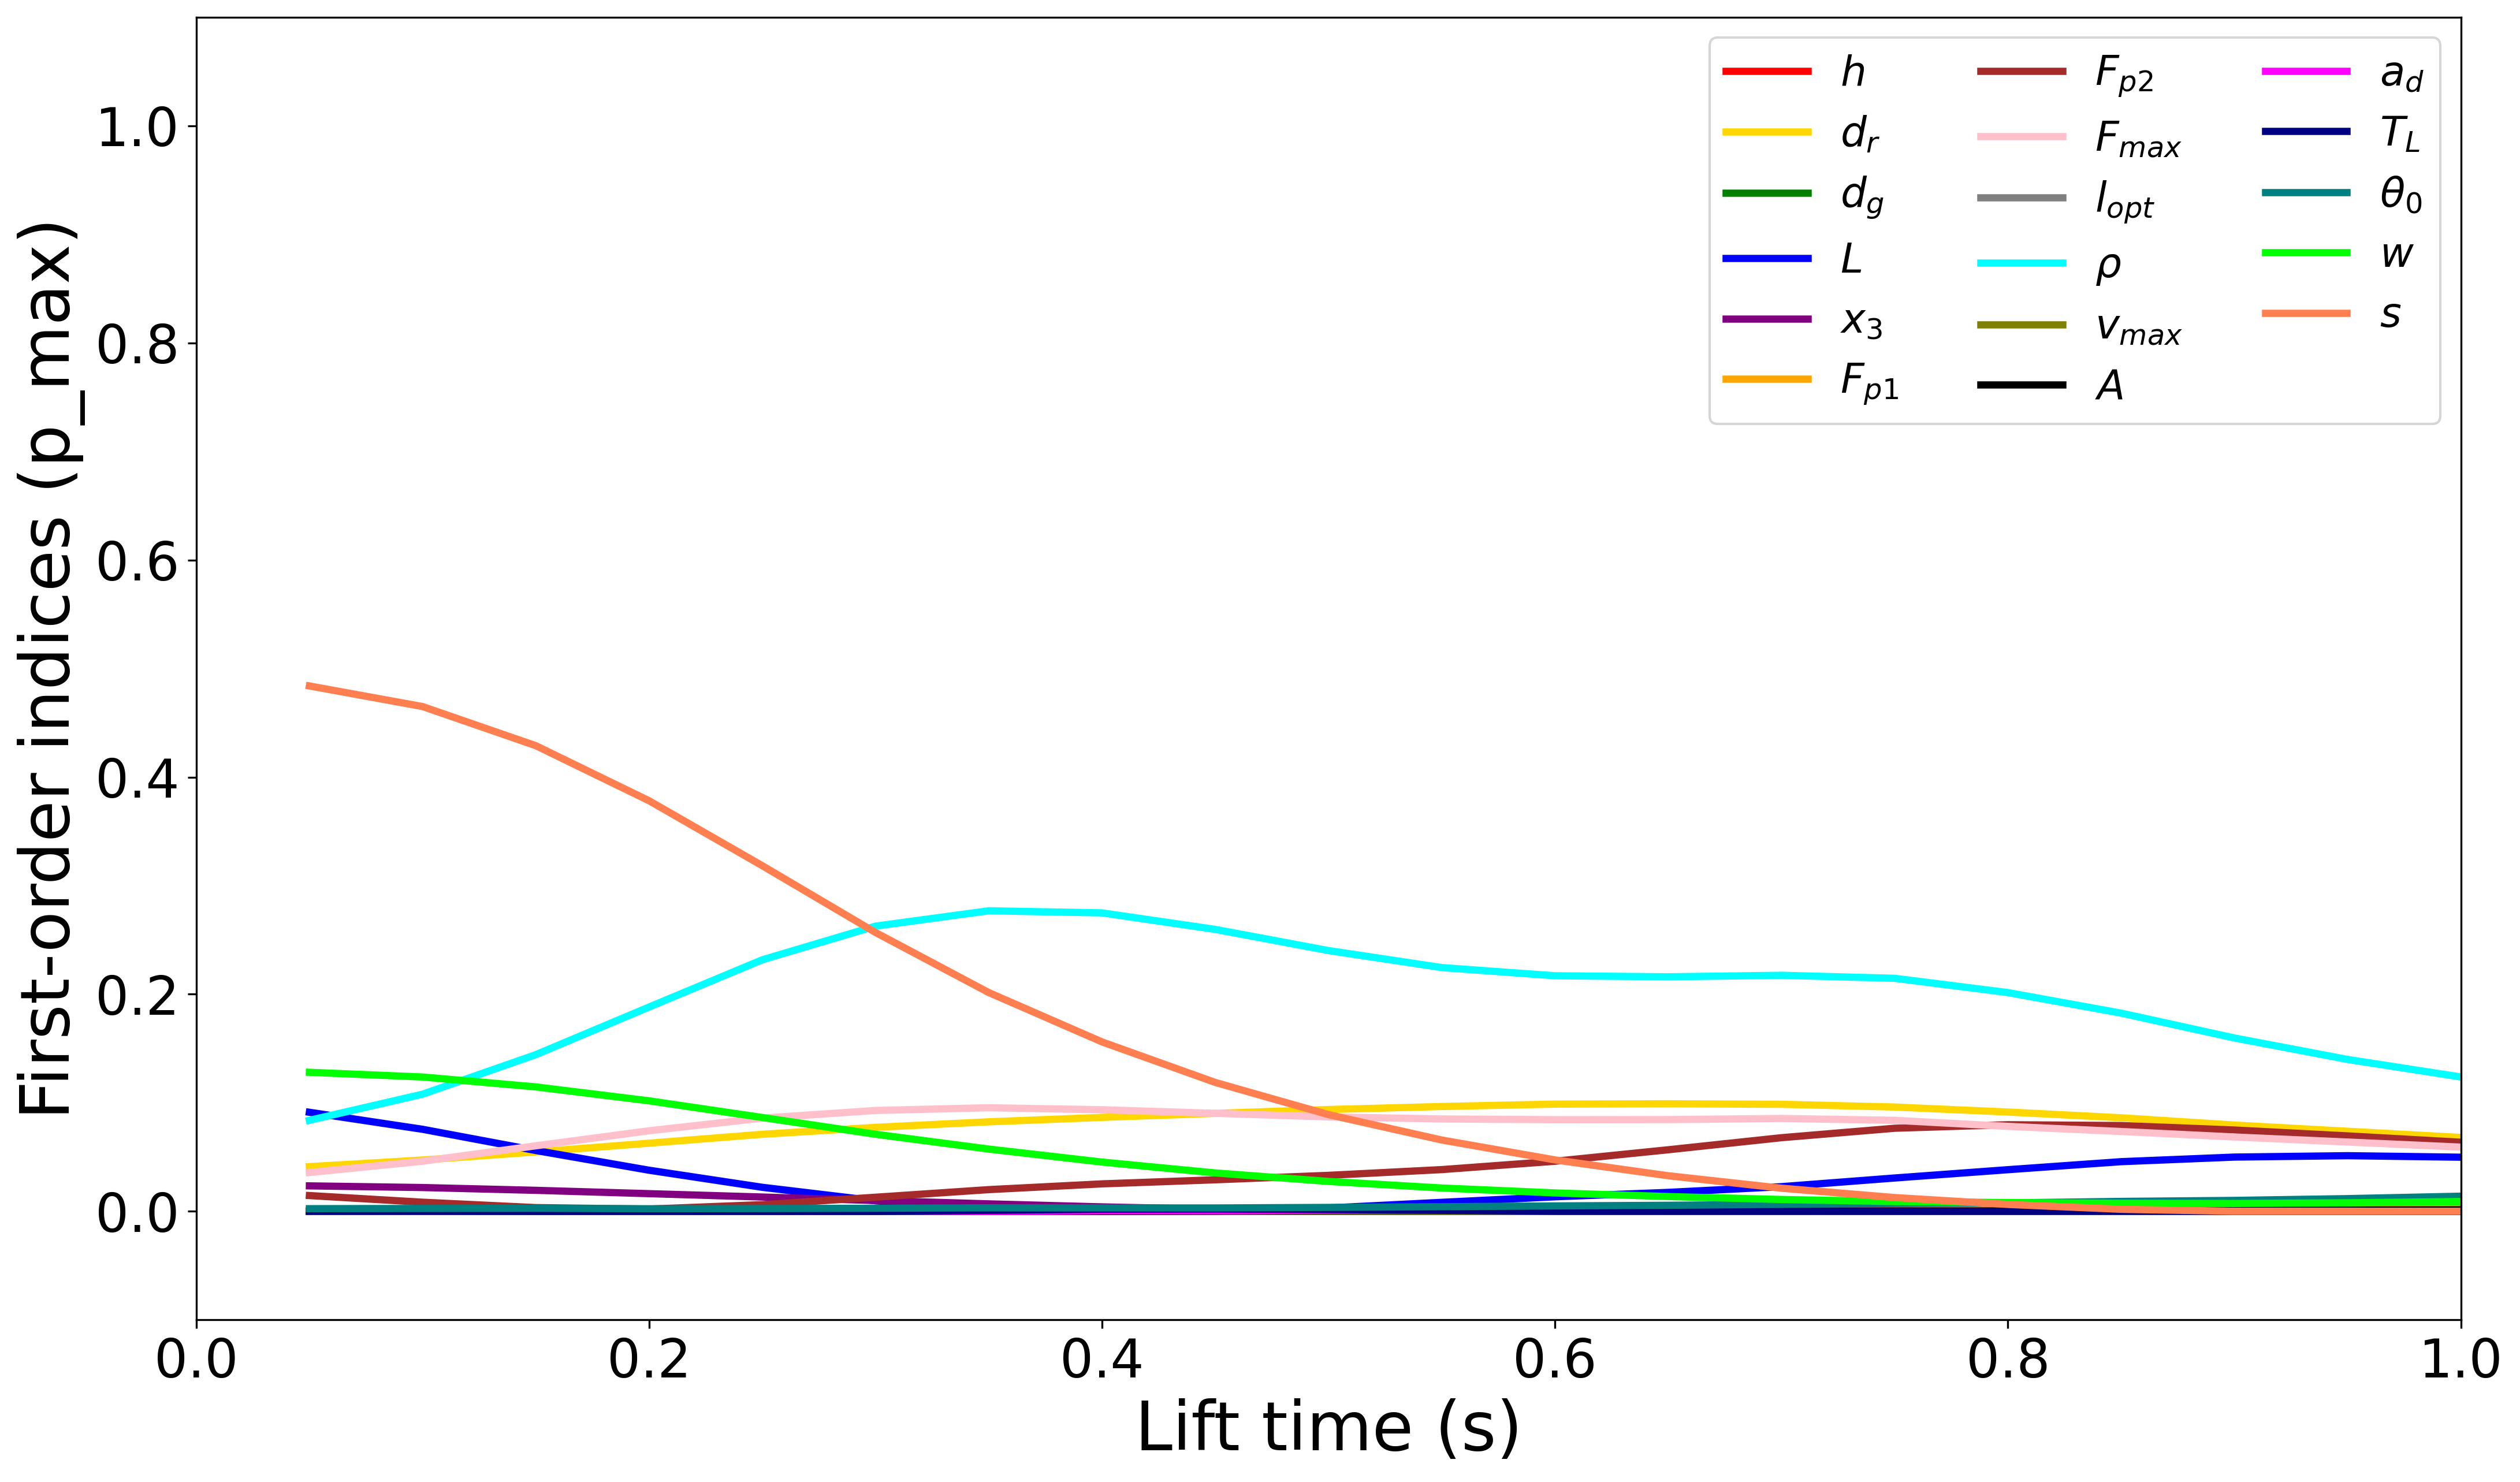

Sensitivity_Total_order_F_m.png


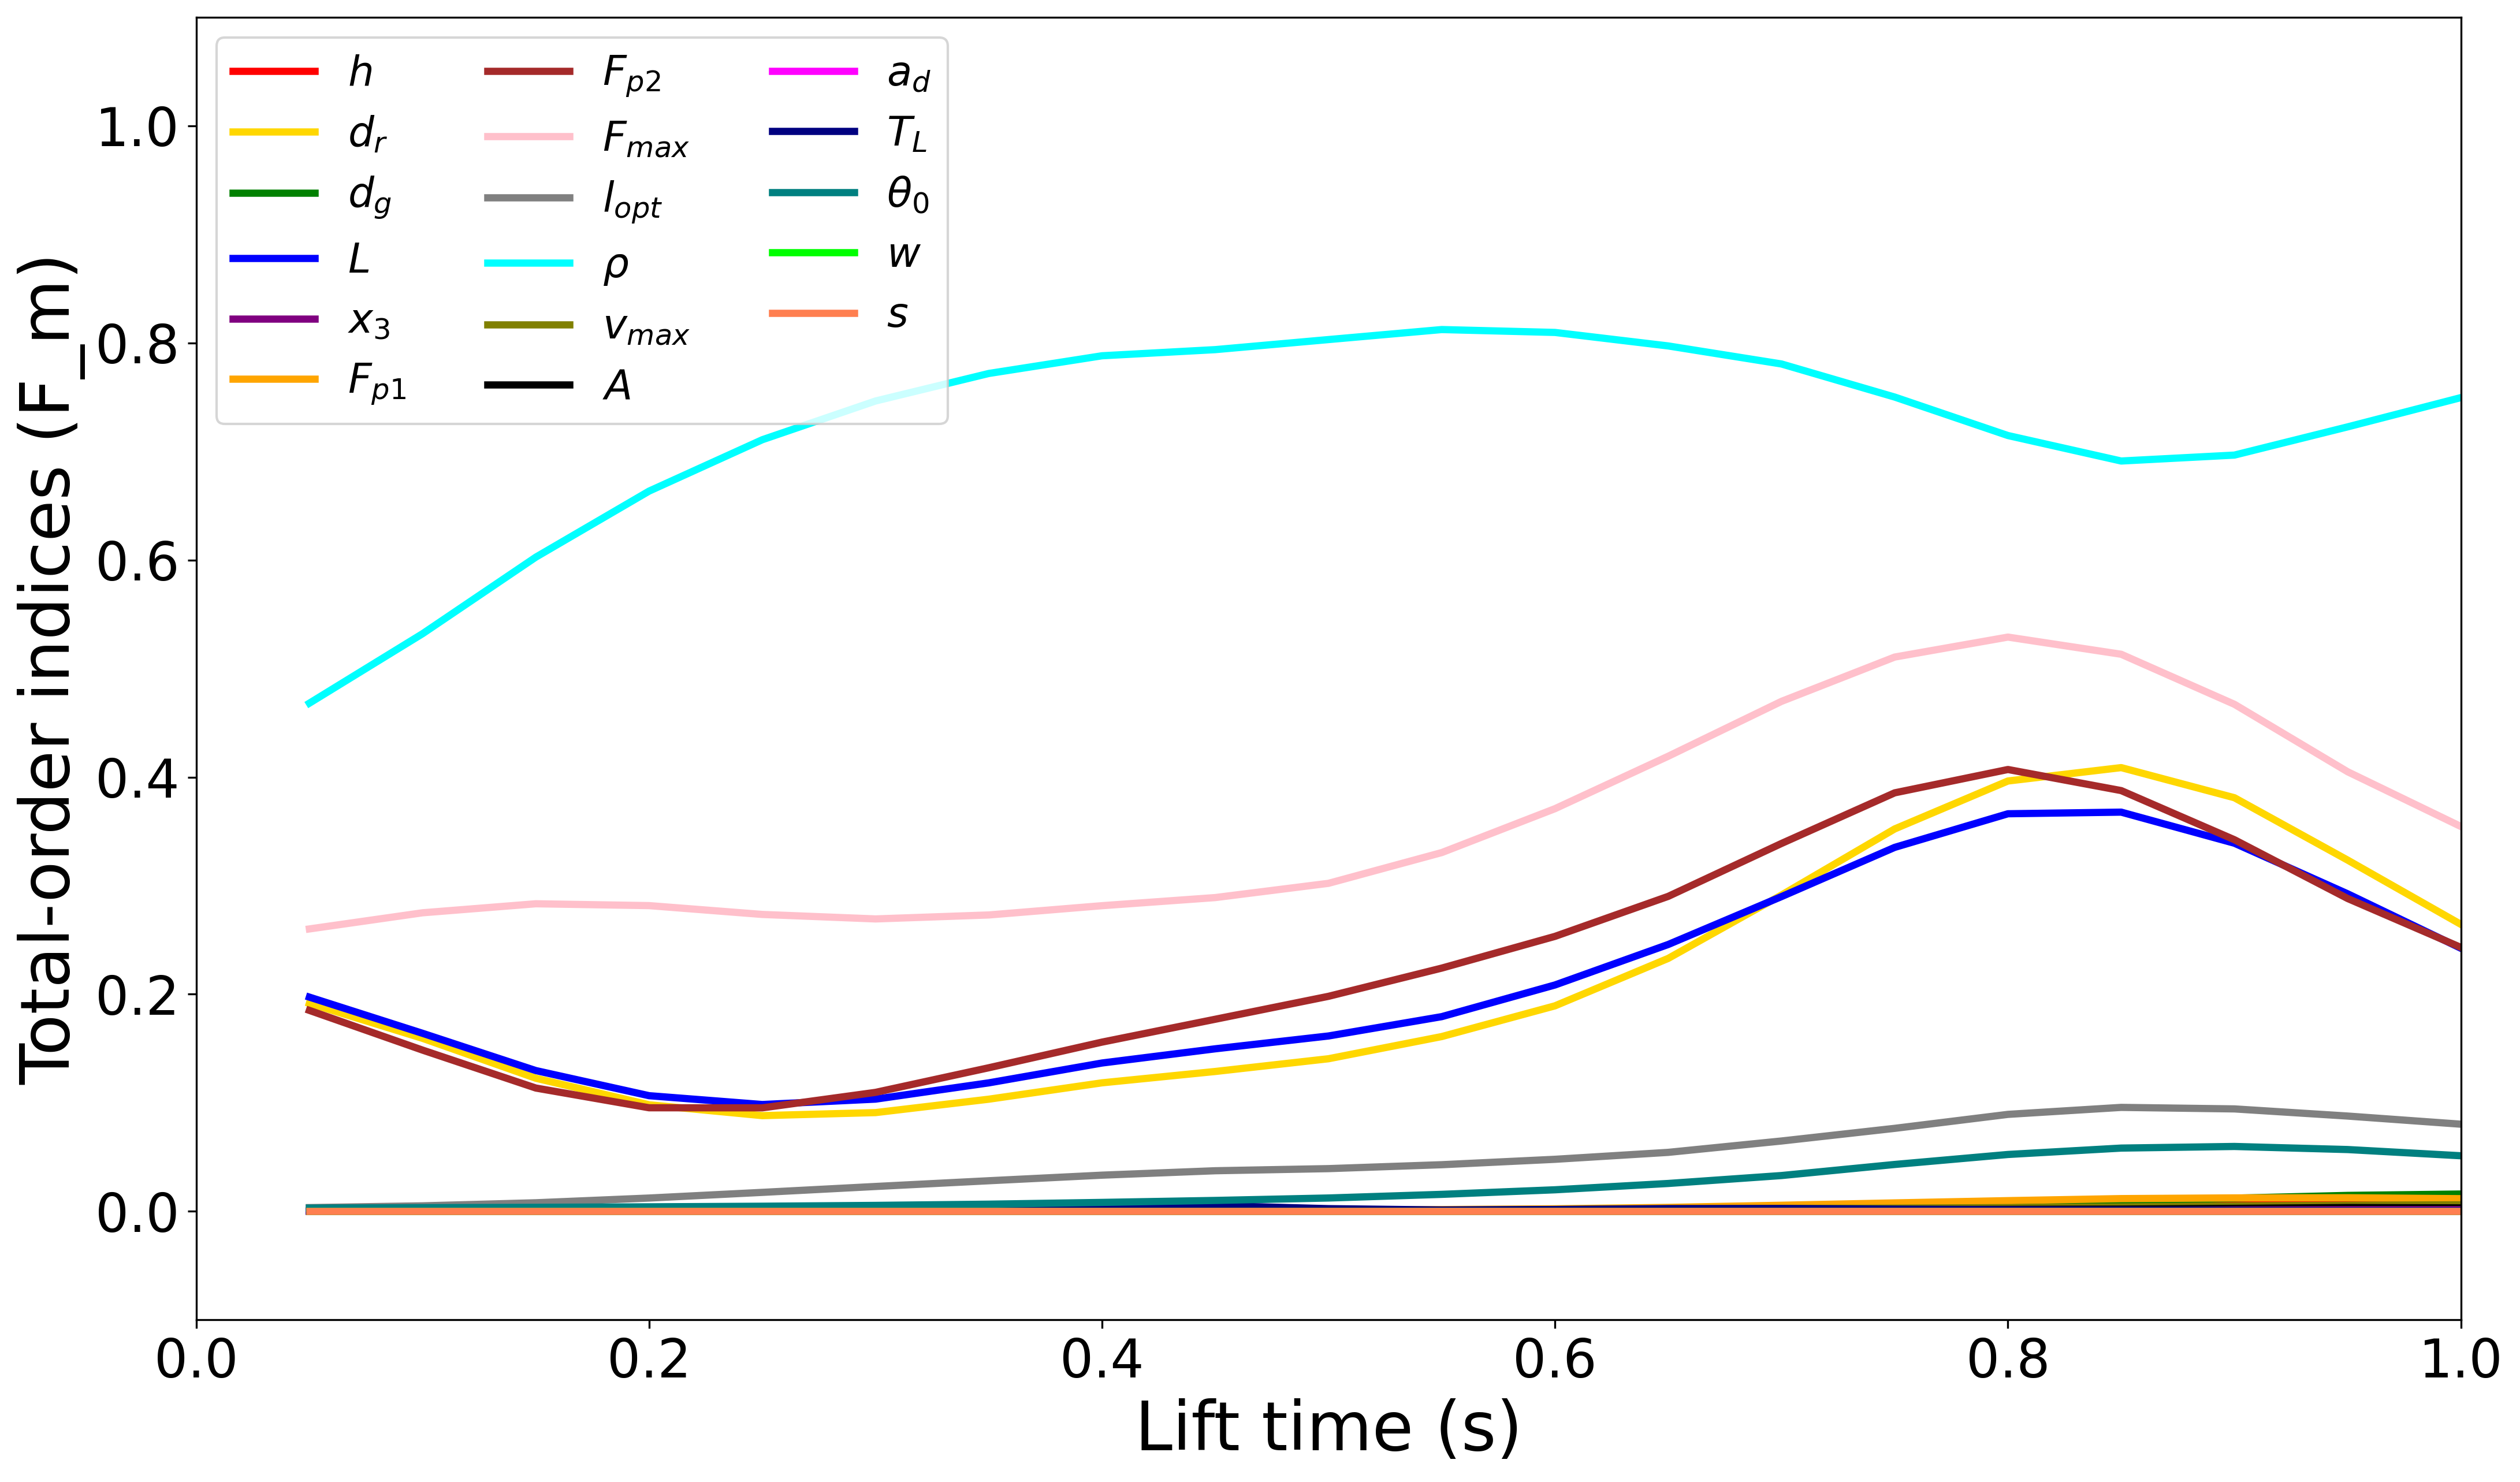

Sensitivity_Total_order_p_max.png


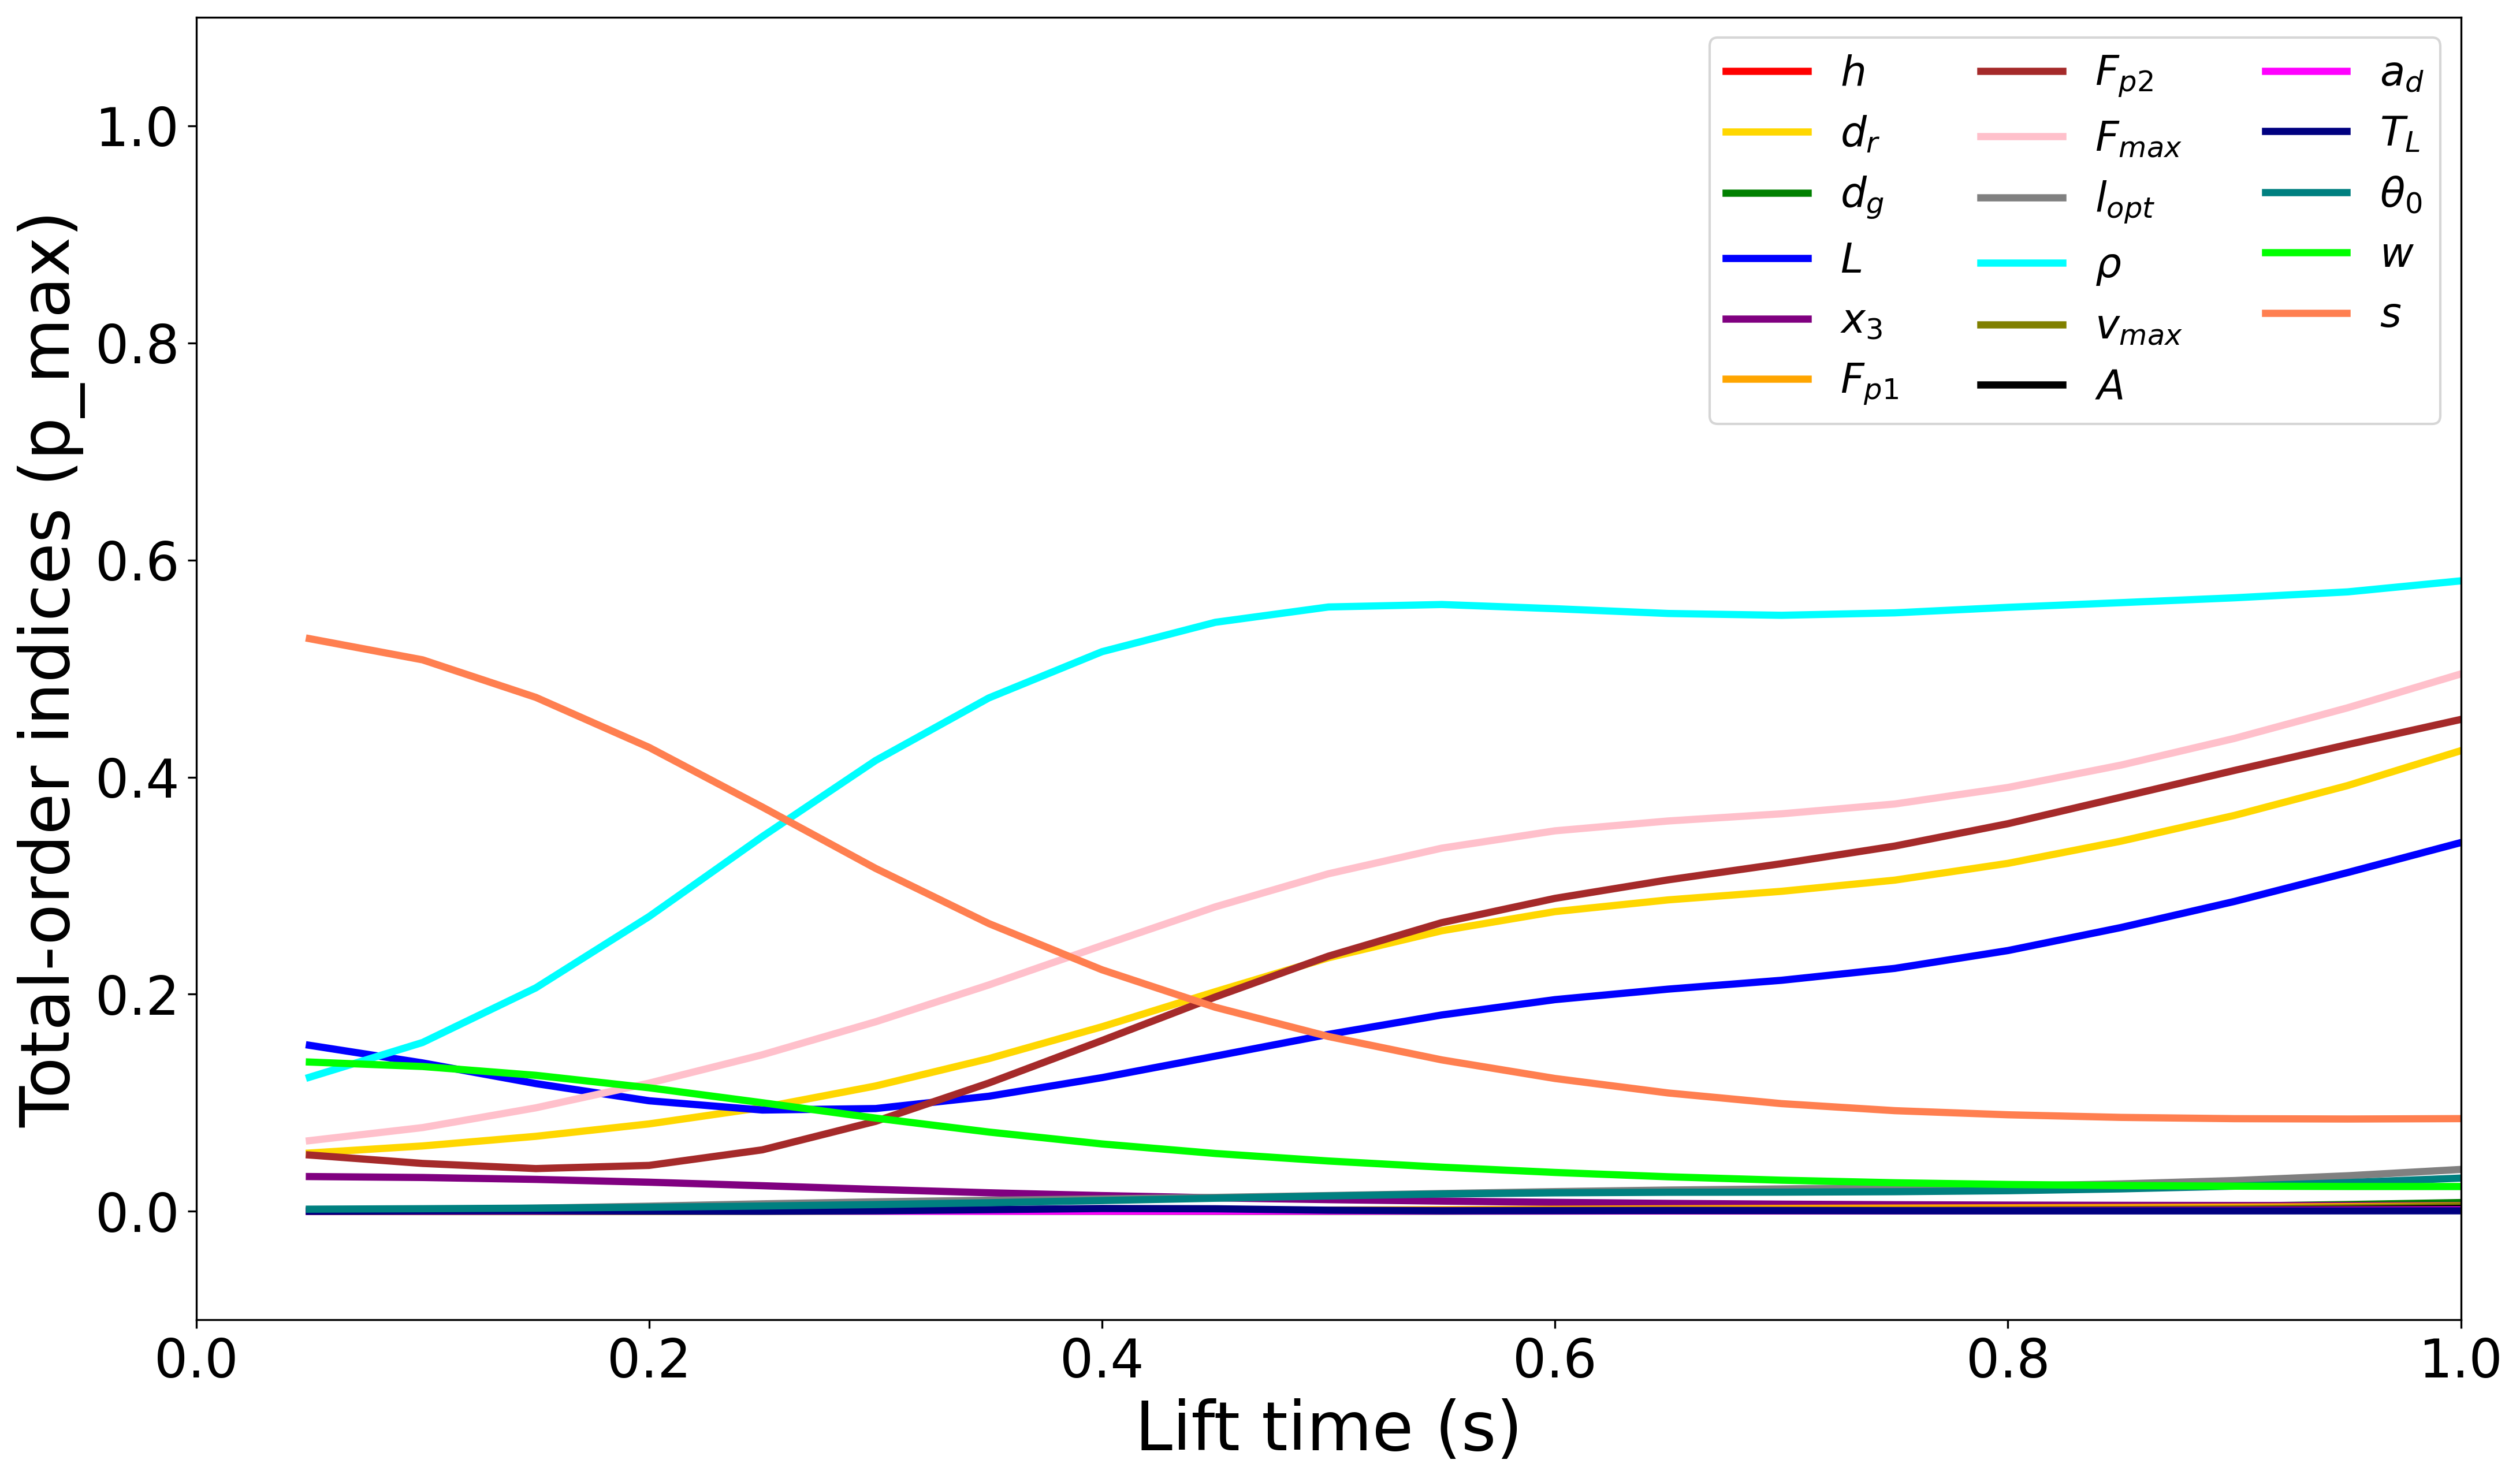

Sensitivity_peak_F_m.png


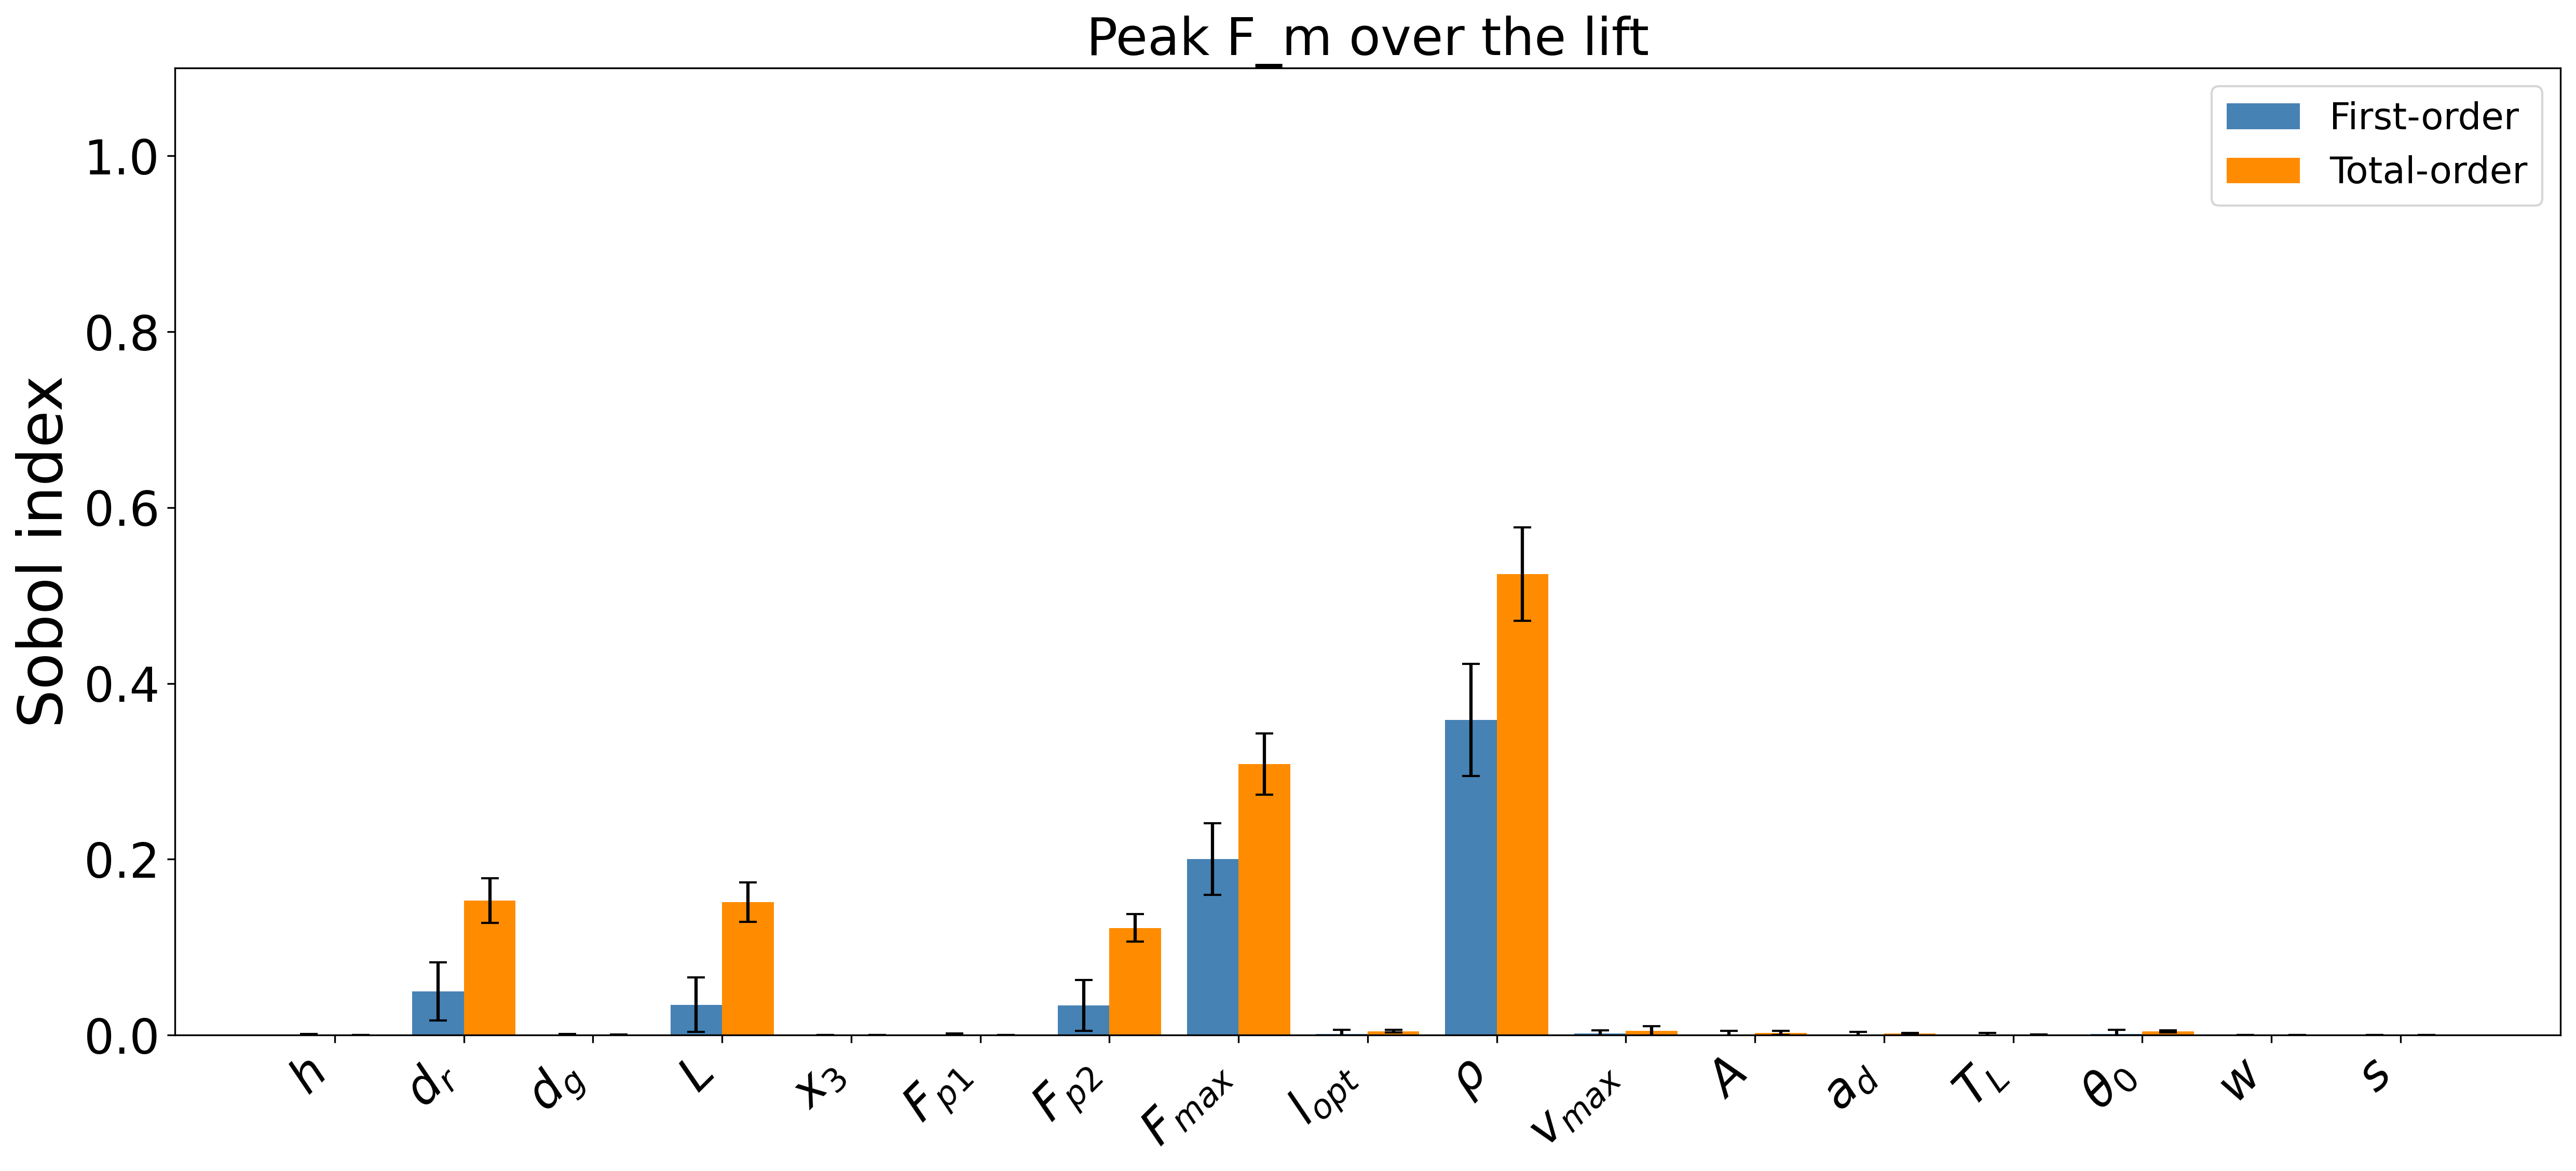

Sensitivity_peak_p_max.png


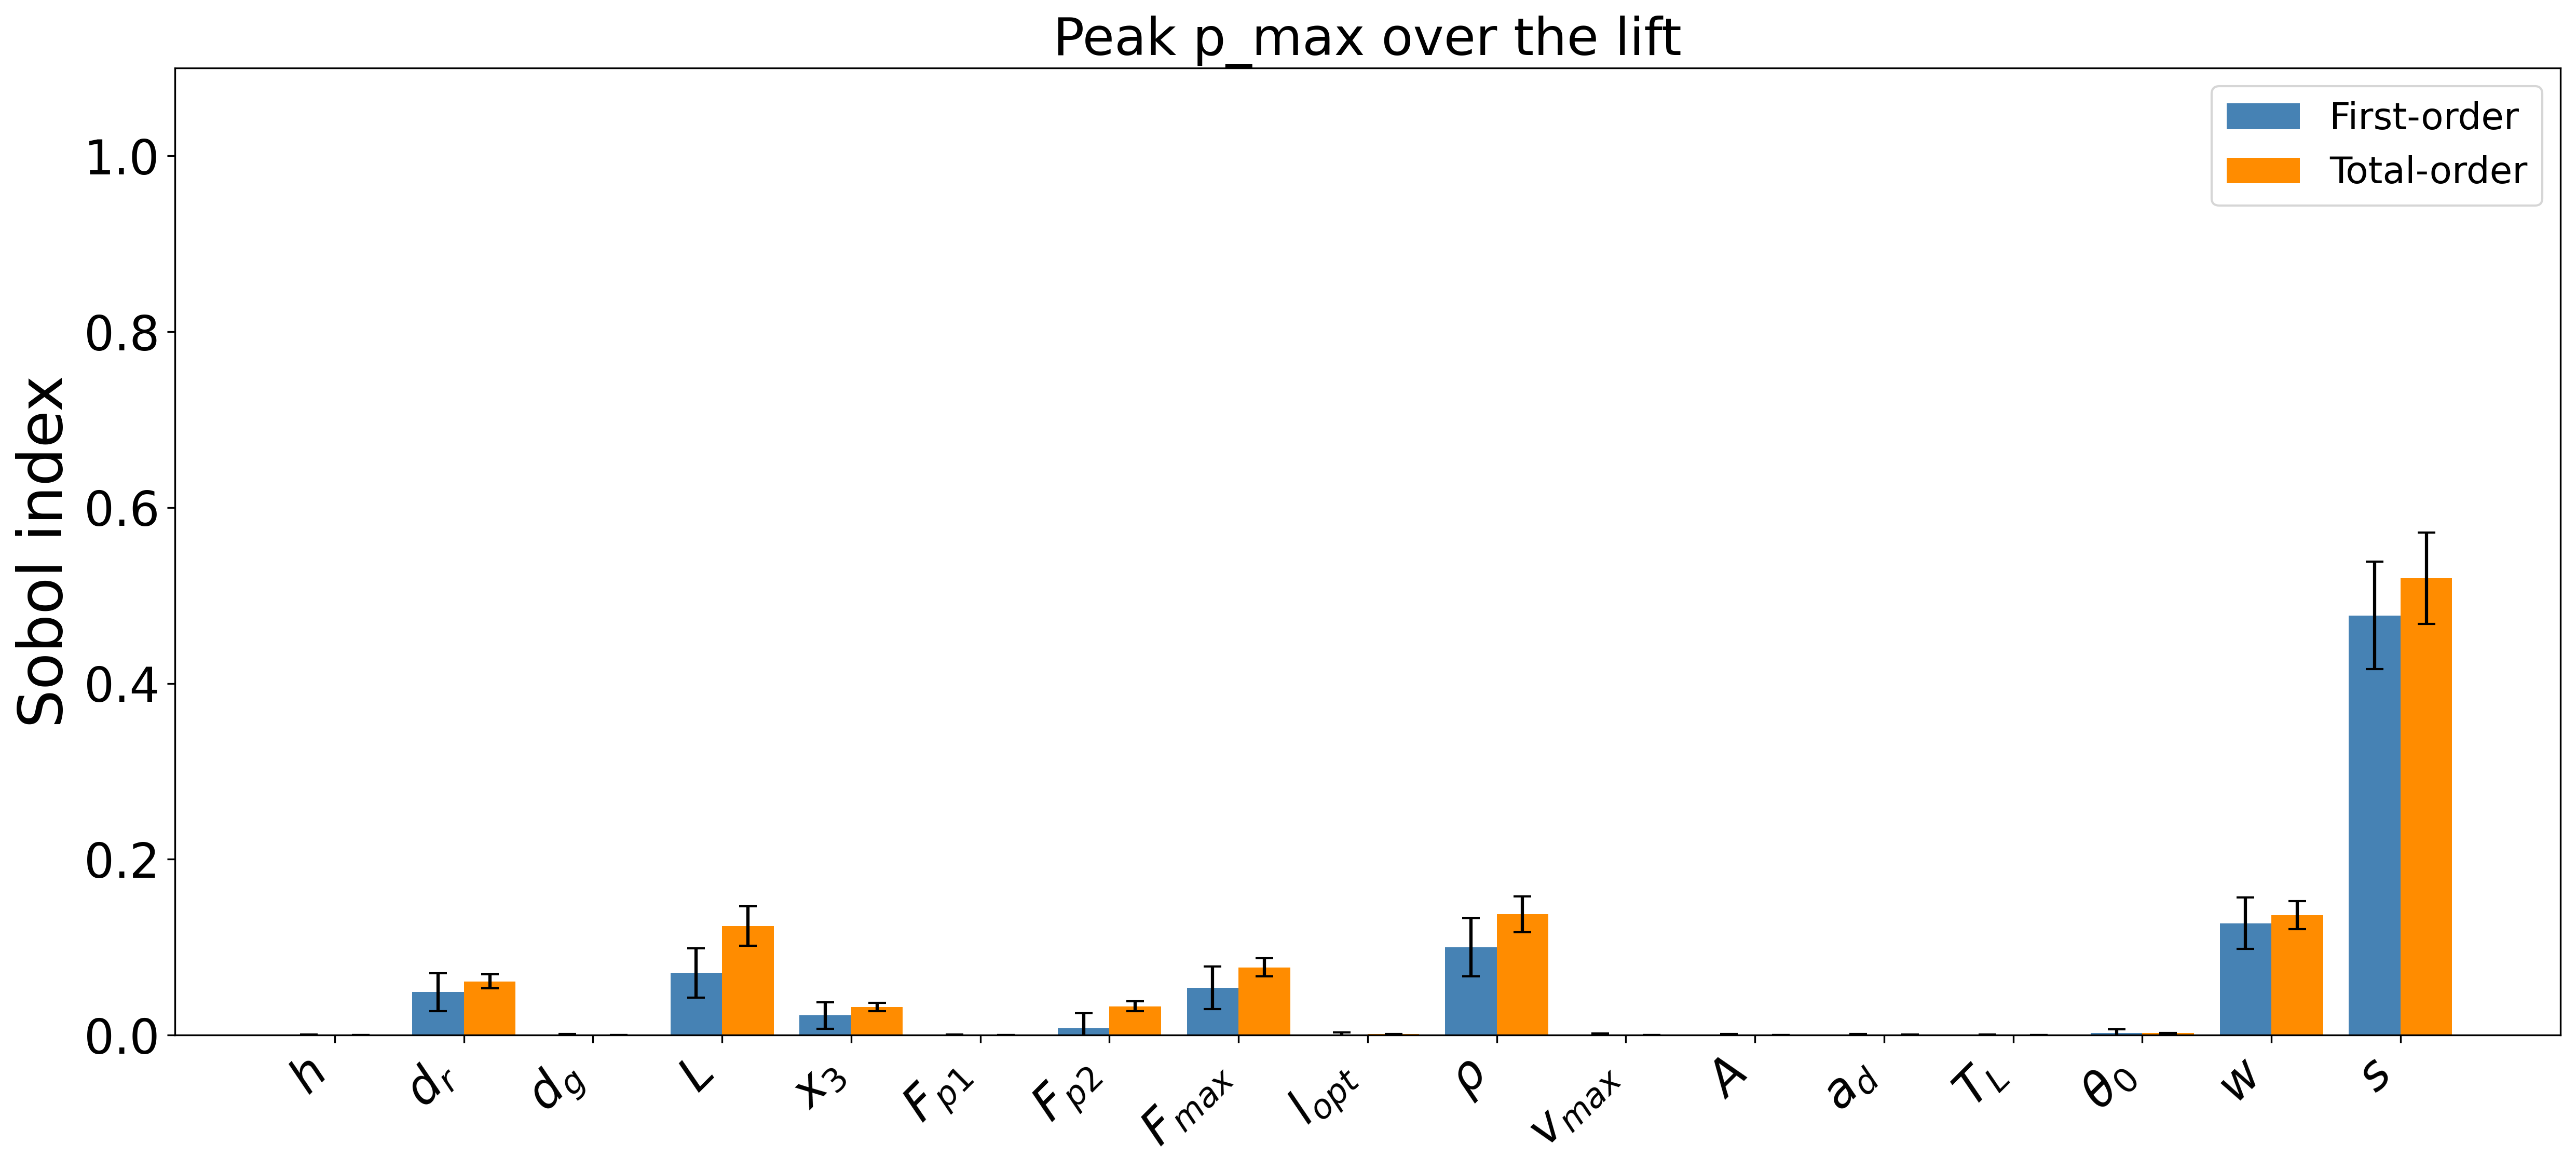

Sensitivity_replace_age_boys.png


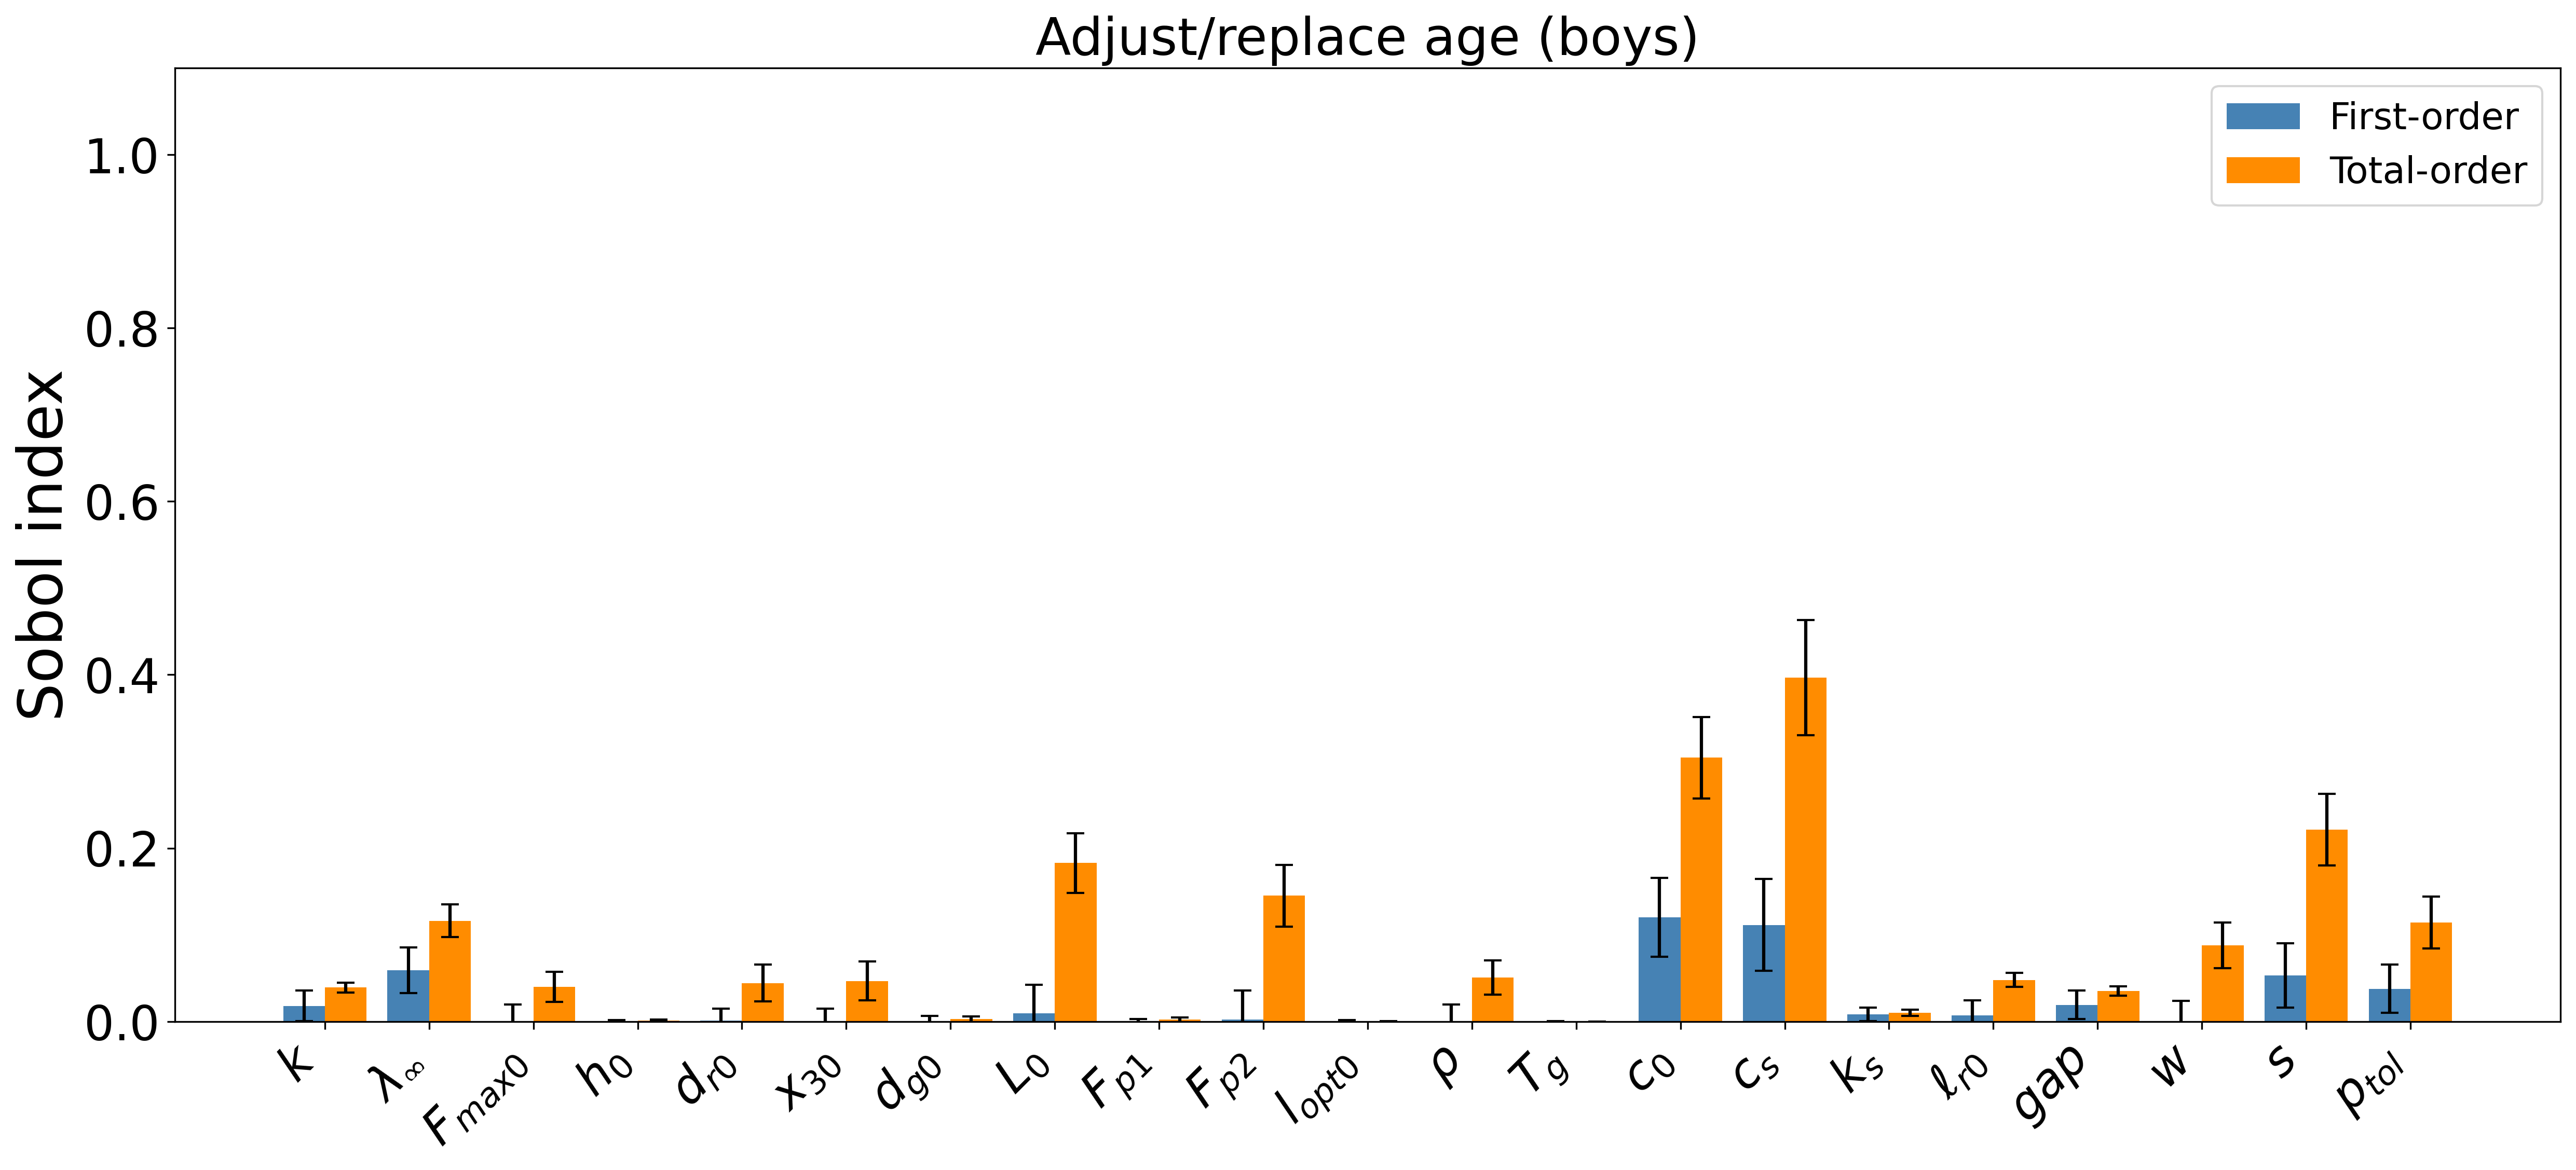

Sensitivity_replace_age_girls.png


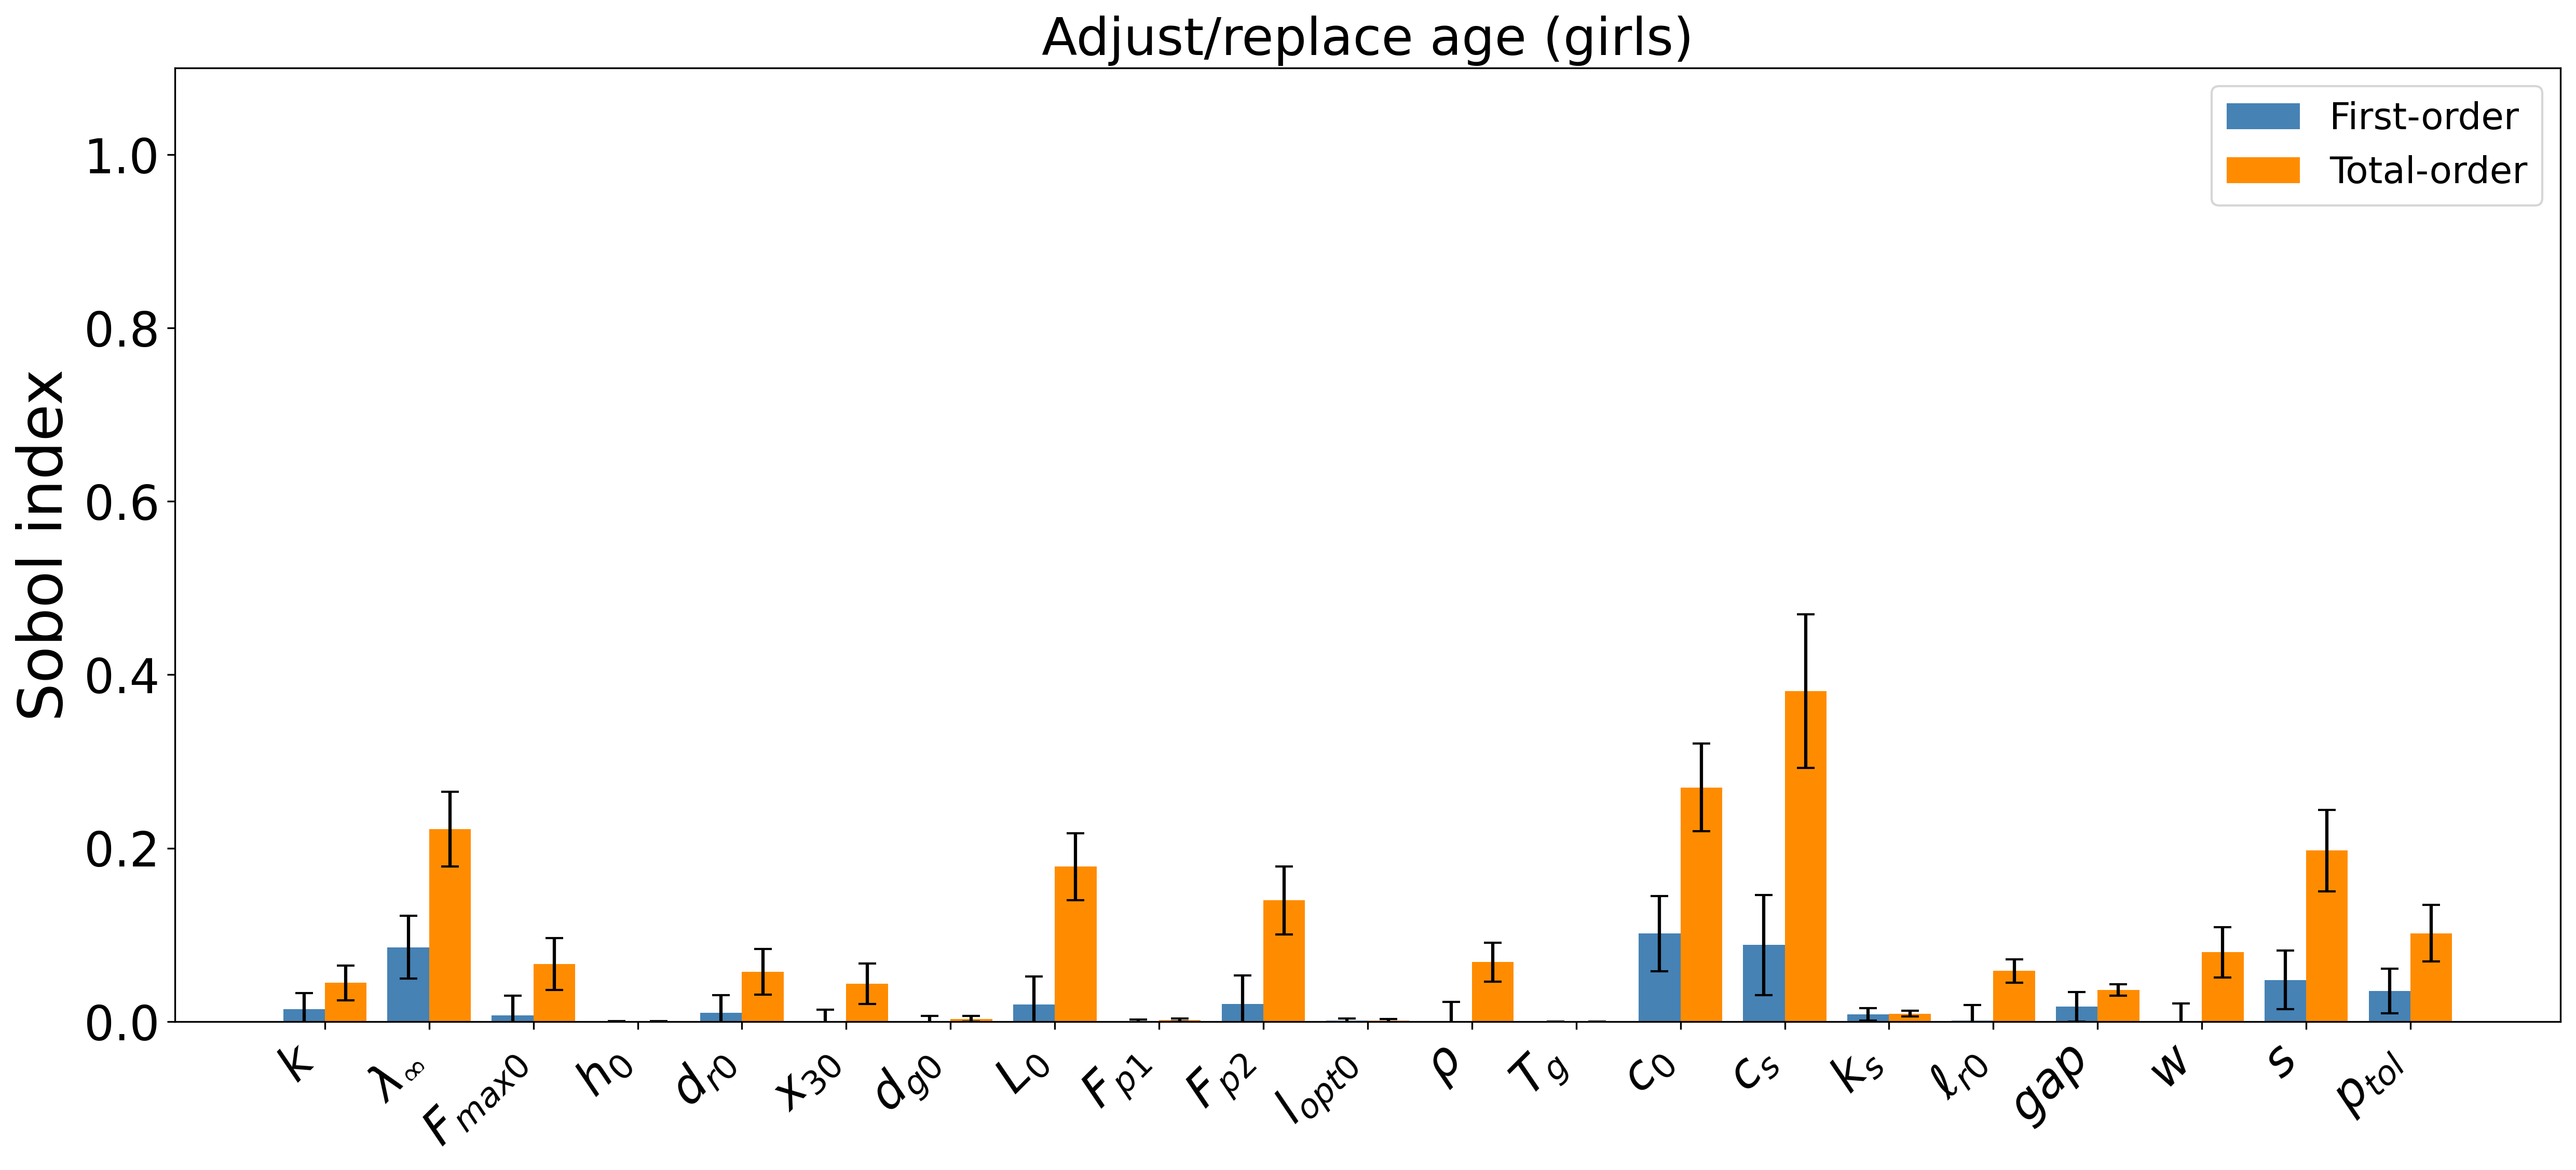

In [5]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("Sensitivity_*.png")):
    print(f); display(Image(f, width=900))